# 미션 9
> 각 클래스에 해당하는 이미지를 생성하는 cGAN (Conditional GAN) 모델을 직접 설계

## 문제 정의 및 목표 설정 (Problem Definition)
### 데이터 소개
데이터 링크: torchvision.datasets.FashionMNIST를 통해 바로 다운로드 가능합니다.
데이터 구성:
- 훈련 데이터: 60,000장의 이미지
- 테스트 데이터: 10,000장의 이미지
- 28×28 크기의 흑백 이미지 (10개 클래스)
클래스 목록:
- T-shirt/top
- Trouser
- Pullover
- Dress
- Coat
- Sandal
- Shirt
- Sneaker
- Bag
- Ankle boot

잘란도(Zalando)가 만든 이 데이터 셋은 머신러닝 알고리즘 벤치마킹을 위한 기존 MNIST데이터셋을 직접 대체할 수 있도록 설계되었으며, 이미지 크기와 훈련 및 테스트 분할 구조가 동일합니다. 이런 데이터셋을 만든 이유는 기존 MNIST보다 머신러닝 및 딥러닝 분류 알고리즘의 성능을 더 까다롭게 테스트하고 비교하기 위해서 입니다. Keras 개발자인 프랑수아 숄레가 2017년 4월 트위터 스레드에서 지적한 내용은 "MNIST는 최신 컴퓨터 비전 작업을 제대로 반영하지 못합니다."라고한다. 그정도로 MNIST는 쉬운 데이터셋이였고 이번 FashionMNIST는 복잡한 모양과 세부 특징, 숫자는 그냥 1의 작대기지만 코트나 풀오버는 실루엣은 같지만 소매, 단추 등 미세한 차이를 구분해내야하며, 옷의 다양한 패턴까지 학습해야해 기존 MNIST보다 어려운 데이터셋을 만들었다고 생각하면 됩니다. 따라서 
> 초등학생 수학 시험(MNIST)에서 만점 받았다고 대학 수학(현대 컴퓨터 비전)을 잘한다고 볼 수 없으니, 최소한 고등학생 수준의 시험지(Fashion-MNIST)로 모델의 실력을 테스트하자!"라는 뜻으로 이해하시면 됩니다.

## 데이터 요구사항 정의 및 수집 (Data Collection)
### 이번 미션 목표
**1. 분석 과정과 결과**
- 데이터 로드, 전처리, cGAN 모델 설계, 학습, 생성 이미지 예측 및 평가 과정을 순차적으로 진행해 주세요.
- 조건부 레이블을 활용해 각 패션 아이템 클래스별로 이미지를 생성하는 모델을 구현하세요.

**2. 마크다운을 활용한 설명**
- 각 코드 셀이 수행하는 작업(의도, 알고리즘, 함수 설명 등)을 마크다운을 통해 자세히 기록해 주세요.
- 노트북 내에서 코드와 결과를 한눈에 이해할 수 있도록 정리해 주세요.

**3. 모델 성능 평가 및 제출**
- 생성된 이미지의 품질을 정성적(시각적 평가) 및 정량적(FID, IS 등, optional)으로 평가해 보세요.
- 테스트 데이터셋에 대한 모델의 조건부 생성 성능을 확인할 수 있는 결과와 함께 Notebook 파일을 제출해 주세요.

**4. 모델 성능 개선해 보기**
- 데이터 증강(Data Augmentation): 이미지 회전, 크롭, 밝기/대비 조절 등으로 모델의 일반화 성능을 높여보세요.
- 하이퍼파라미터 튜닝: 학습률, 배치 크기, 에폭 수 등을 조정하여 최적의 성능을 도출해 보세요.
- 모델 구조 개선: 조건부 생성 네트워크에 추가적인 레이어 등을 도입하여 성능 개선을 시도해 보세요.

| 구성 | 표기법 | 어떻게 사용하는가? |
| --- | --- | --- |
| 인용 | > | 예측 또는 결과에서는 인용을 사용한다. |
| 강조 | ** | 인용문구에서 가장 중요한 점을 표기한다. |

## 환경 설정 및 데이터 불러오기
- 필요한 라이브러리 import
- 시각화를 위한 한글폰트 설정하기
- FashionMNIST 학습·테스트데이터 불러오기

# 실험 및 모델 학습관련 😊 공통 사용
> 추가 셀을 사용할 수 있으나 기존 셀을 활용하여 실시

In [12]:
# 장치 불러오기
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

In [3]:
# 학습장치 확인
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [5]:
# 한글 설정하기
!uv pip install koreanize-matplotlib

Using Python 3.14.7 environment at: /Users/codeit/CodeIt-ouo/.venv
Resolved 12 packages in 828ms                                        
Prepared 12 packages in 9.36s                                                matplotlib           ------------------------------ 8.84 MiB/8.88 MiB           matplotlib           ------------------------------ 7.55 MiB/8.88 MiB           matplotlib           ------------------------------ 5.25 MiB/8.88 MiB           matplotlib           ------------------------------ 4.72 MiB/8.88 MiB           matplotlib           ------------------------------ 2.87 MiB/8.88 MiB           matplotlib           ------------------------------ 256.00 KiB/8.88 MiB         matplotlib           ------------------------------ 128.00 KiB/8.88 MiB         matplotlib           ------------------------------ 79.74 KiB/8.88 MiB          matplotlib           ------------------------------ 64.00 KiB/8.88 MiB          Amatplotlib           ------------------------------ 32.00 KiB/8.8

In [7]:
# 데이터 불러오기

import torchvision

train_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True
)

test_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True
)

100%|██████████| 26.4M/26.4M [00:09<00:00, 2.89MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 82.7kB/s]
100%|██████████| 4.42M/4.42M [00:03<00:00, 1.41MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.7MB/s]


## 데이터 탐색 및 분석 (EDA)
- 목적: 정리되어 제공되는 데이터의 구조와 이미지·라벨 상태를 확인하고, 학습에 필요한 전처리를 결정한다.
- 학습·테스트 데이터 개수 확인
- 이미지 크기, 채널, 자료형, 픽셀 값 범위 확인
- 라벨 자료형과 클래스 이름·번호 매핑 확인
- 클래스별 이미지 장수와 분포 확인
- 이미지와 라벨의 전체 개수 일치 여부 확인
- 클래스별 샘플을 출력해 이미지와 라벨이 맞는지 확인
- 클래스별 이미지를 랜덤으로 10장씩 출력하여 형태, 위치, 크기와 밝기가 얼마나 다른지 살펴본다.
- 클래스별 평균 이미지에서 공통적인 형태를 확인한다.
- 픽셀별 표준편차 이미지에서 밝게 나타나는 영역을 통해 이미지 간 픽셀 밝기 변화가 큰 위치를 확인한다.

In [ ]:
# 학습, 데이터 개수 확인

print("학습 데이터 개수:", len(train_dataset))
print("테스트 데이터 개수:", len(test_dataset))

학습 데이터 개수: 60000
테스트 데이터 개수: 10000


In [ ]:
# 이미지 크기, 채널, 자료형, 픽셀 값 범위 확인
# 의사코드
# 학습, 테스트 데이터 각각 위 print처럼 보일 수 있도록한다.
import numpy as np

image, label = train_dataset[0] # 학습데이터 확인
image_array = np.array(image) # 이미지의 픽셀 숫자를 살펴보려고 만든 NumPy 배열

print("원본 이미지 자료형:", type(image))
print("이미지 크기 (너비, 높이):", image.size)
print("이미지 모드:", image.mode) # 이미지에 설정되어 있는 표현 방식을 읽는 속성

print("배열 shape:", image_array.shape)
print("픽셀 데이터 타입:", image_array.dtype)
print("최솟값:", image_array.min())
print("최댓값:", image_array.max())
print("라벨:", label)

원본 이미지 자료형: <class 'PIL.Image.Image'>
이미지 크기 (너비, 높이): (28, 28)
이미지 모드: L
배열 shape: (28, 28)
픽셀 데이터 타입: uint8
최솟값: 0
최댓값: 255
라벨: 9


In [ ]:
import numpy as np

image, label = test_dataset[0] # 테스트 데이터 확인
image_array = np.array(image) # 이미지의 픽셀 숫자를 살펴보려고 만든 NumPy 배열

print("원본 이미지 자료형:", type(image))
print("이미지 크기 (너비, 높이):", image.size)
print("이미지 모드:", image.mode) # 이미지에 설정되어 있는 표현 방식을 읽는 속성

print("배열 shape:", image_array.shape)
print("픽셀 데이터 타입:", image_array.dtype)
print("최솟값:", image_array.min())
print("최댓값:", image_array.max())
print("라벨:", label)

원본 이미지 자료형: <class 'PIL.Image.Image'>
이미지 크기 (너비, 높이): (28, 28)
이미지 모드: L
배열 shape: (28, 28)
픽셀 데이터 타입: uint8
최솟값: 0
최댓값: 255
라벨: 9


> 두 데이터 타입이 완전히 같다는 점을 확인했다.

이미지에 설정되어 있는 표현 방식을 읽는 속성
<br> 라이브러리인 Pillow(PIL)에서의 정의

| 모드 | 의미 | 픽셀 하나의 정보 |
|---|---|---|
| `L` | 흑백 이미지 | 밝기 값 1개 |
| `RGB` | 컬러 이미지 | 빨강·초록·파랑 값 3개 |
| `RGBA` | 투명도를 포함한 컬러 이미지 | 색상 값 3개 + 투명도 1개 |

In [ ]:
# 라벨 자료형과 클래스 이름·번호 매핑 확인
print("라벨 자료형:", type(label))
print("학습 클래스 이름 목록:", train_dataset.classes)
print("테스트 클래스 이름 목록:", test_dataset.classes)
print("클래스 매칭 일치:", train_dataset.class_to_idx == test_dataset.class_to_idx)

# 위에서 매칭을 확인하여 아래에서는 학습 클래스 번호만 확인하여 어떻게 매핑됬는지를 본다. 
print("학습 클래스 번호 확인:", train_dataset.class_to_idx)


라벨 자료형: <class 'int'>
학습 클래스 이름 목록: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
테스트 클래스 이름 목록: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
클래스 매칭 일치: True
학습 클래스 번호 확인: {'T-shirt/top': 0, 'Trouser': 1, 'Pullover': 2, 'Dress': 3, 'Coat': 4, 'Sandal': 5, 'Shirt': 6, 'Sneaker': 7, 'Bag': 8, 'Ankle boot': 9}


In [18]:
# 클래스별 이미지 장수와 분포 확인
for idx, class_name in enumerate(train_dataset.classes):
    count = (train_dataset.targets == idx).sum().item()
    print(f"{idx}: {class_name} → {count}장")

0: T-shirt/top → 6000장
1: Trouser → 6000장
2: Pullover → 6000장
3: Dress → 6000장
4: Coat → 6000장
5: Sandal → 6000장
6: Shirt → 6000장
7: Sneaker → 6000장
8: Bag → 6000장
9: Ankle boot → 6000장


In [19]:
# 이미지와 라벨의 전체 개수 일치 여부 확인
# 위에서 매핑 확인이 됬으므로 넘어간다

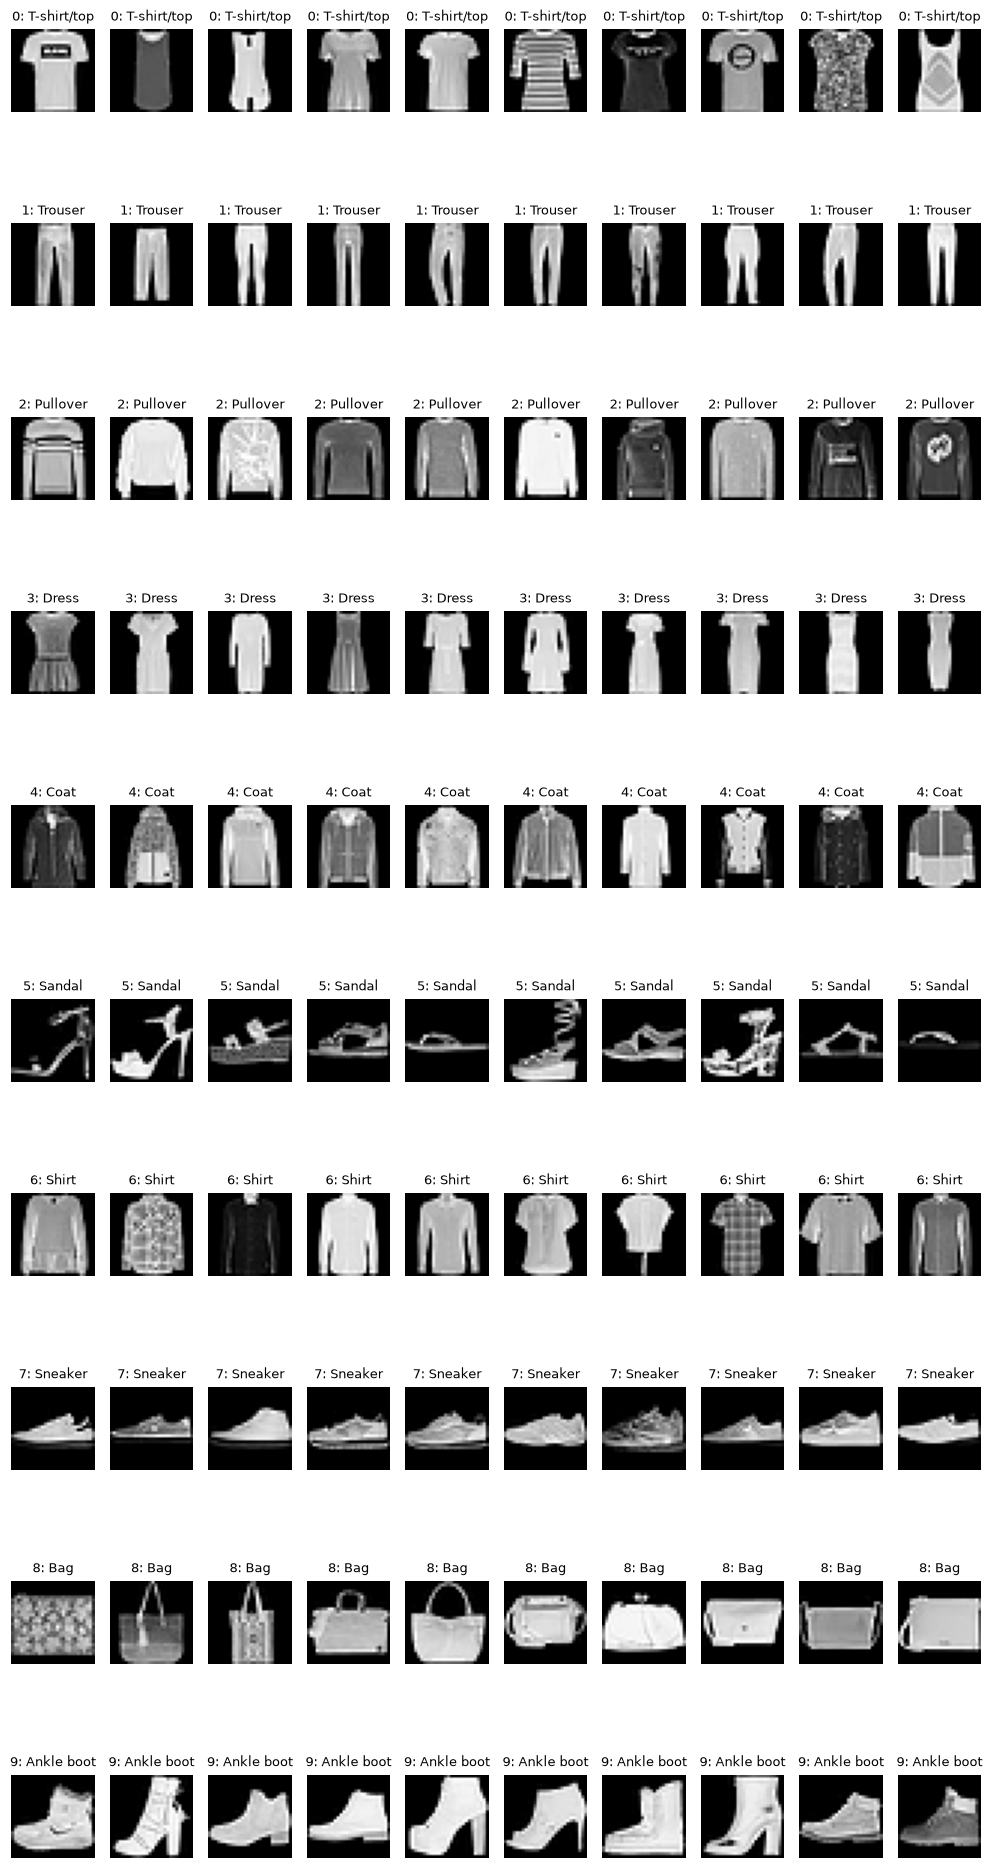

In [ ]:
# 클래스별 샘플을 출력해 이미지와 라벨이 맞는지 확인
import matplotlib.pyplot as plt

n_samples = 10 # 출력수를 결정

fig, axes = plt.subplots(
    len(train_dataset.classes),
    n_samples,
    figsize=(10, 20) # 출력물의 싸이즈 결정
)

for idx, class_name in enumerate(train_dataset.classes): 
    # enumerate : for 문 안에서 반복 가능한(iterable) 객체(리스트, 튜플, 문자열 등)를 입력받아 인덱스(index)와 원소(element)의 쌍을 튜플 형태로 반환하는 내장 함수
    # 해당 클래스의 이미지 위치 중 앞에서 내가 정한 출력수만큼 선택
    image_indices = (
        (train_dataset.targets == idx) # 타겟 번호를 확인 후에, 
        .nonzero() # .nonzero()로 True인 위치 찾기
        .flatten()[:n_samples]
        .tolist()
    )

    for col, image_idx in enumerate(image_indices):
        image, label = train_dataset[image_idx]

        axes[idx, col].imshow(image, cmap="gray")
        axes[idx, col].set_title(f"{label}: {class_name}", fontsize=9)
        axes[idx, col].axis("off")

plt.tight_layout()
plt.show()

> 클래스별로 잘 묶여있지만 조금씩 다르다. 
>
> 특이사항 1. 티셔츠나 셔츠, 원피스등에서 슬리브리스도 있고, 하프슬리브, 롱슬리브가 있고 스니커즈도 하이탑도 있고 로우탑도 있다. 이런 점들을 고려해서 데이터 증강을 고려한다.
> 2. 얼빡샷처럼 전체적으로 이미지가 중앙에 있고 28x28에 꽉차있어 크롭은 안해도 괜찮아보인다.

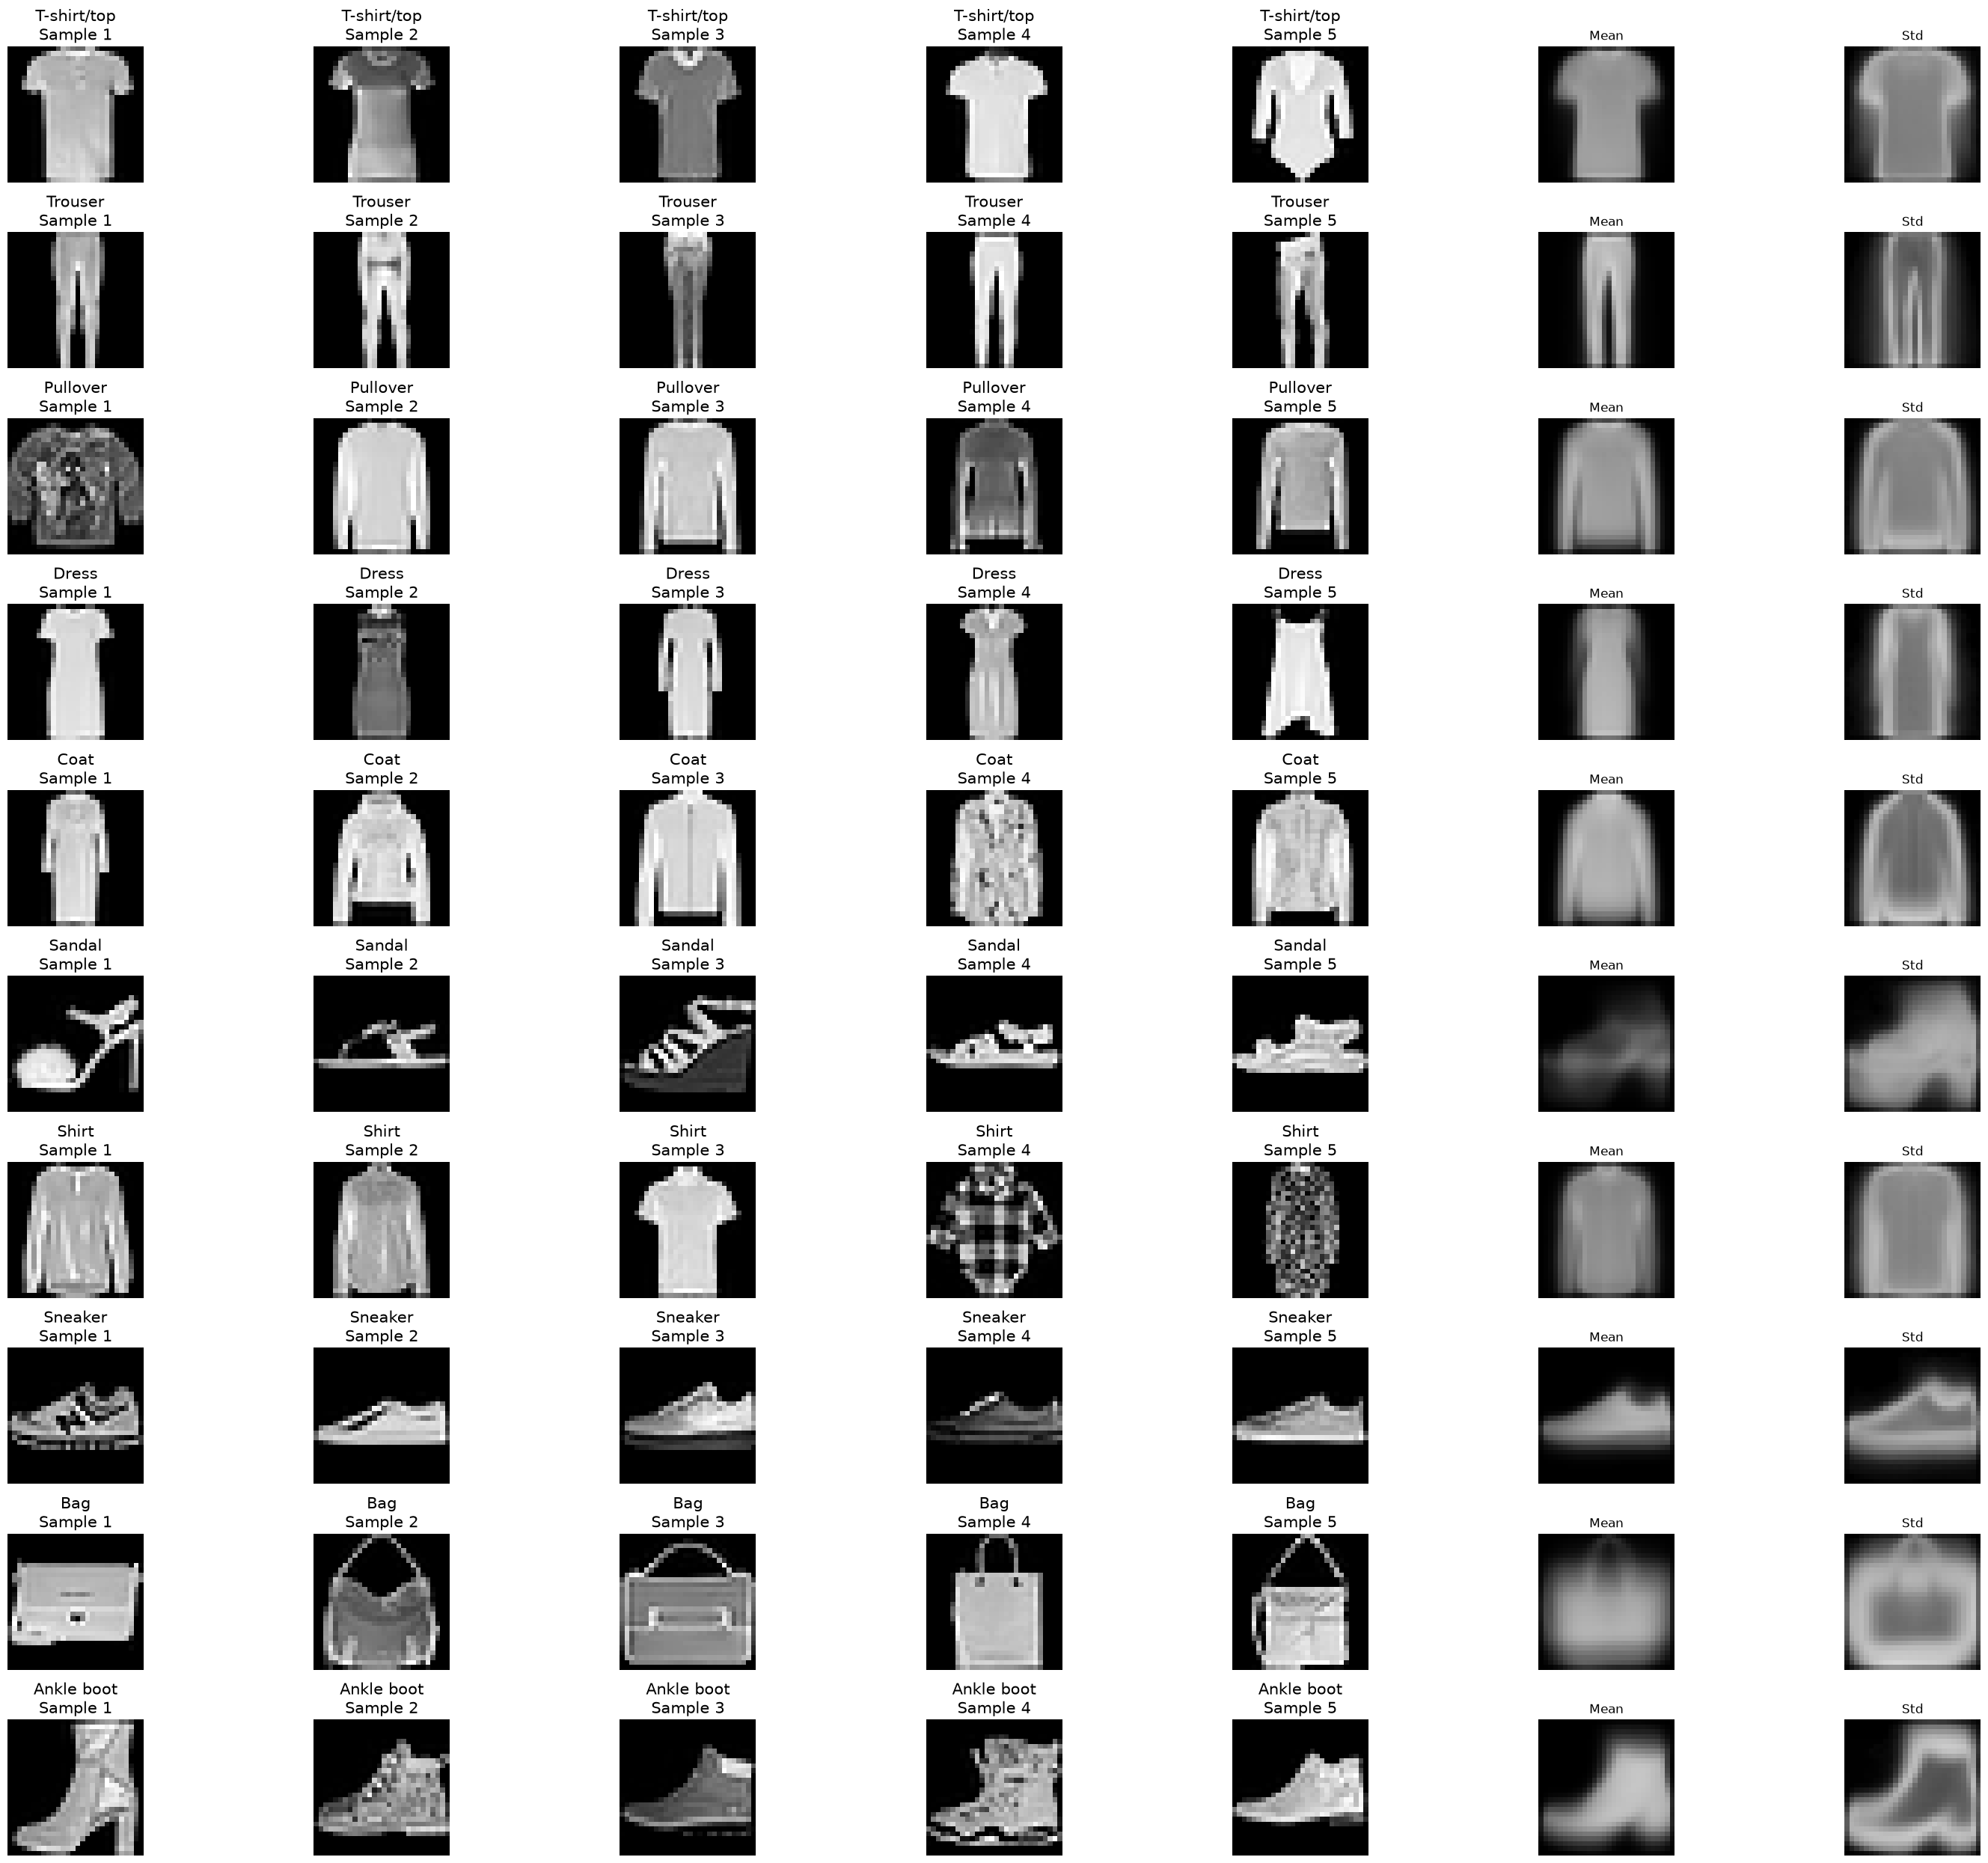

In [ ]:
# 클래스별 이미지의 공통점과 다양성 확인
import numpy as np
import matplotlib.pyplot as plt

# 원본 픽셀을 0~1 범위의 배열로 준비
pixels = train_dataset.data.numpy().astype(np.float32) / 255.0
targets = train_dataset.targets.numpy()

rng = np.random.default_rng(42)  # 같은 샘플로 다시 확인하기
n_samples = 5

fig, axes = plt.subplots(
    len(train_dataset.classes),
    n_samples + 2,
    figsize=(30, 25)
)

for idx, name in enumerate(train_dataset.classes):
    class_indices = np.flatnonzero(targets == idx)
    sample_indices = rng.choice(
        class_indices, size=n_samples, replace=False
    )

    # 클래스별 랜덤 이미지 5장
    for col, image_idx in enumerate(sample_indices):
        axes[idx, col].imshow(
            pixels[image_idx], cmap="gray", vmin=0, vmax=1
        )
        axes[idx, col].set_title(f"{name}\nSample {col + 1}", fontsize=15) # 위에 붙는 이름들 싸이즈

    # 랜덤 5장이 아닌, 해당 클래스 전체로 통계 계산
    class_pixels = pixels[class_indices]
    mean_image = class_pixels.mean(axis=0) # axis=0은 이미지 장수 방향으로 계산한다는 뜻
    std_image = class_pixels.std(axis=0)

    axes[idx, 5].imshow(
        mean_image, cmap="gray", vmin=0, vmax=1
    )
    axes[idx, 5].set_title("Mean")

    # 0~1 픽셀의 표준편차는 최대 0.5: 모든 클래스에 같은 척도 적용
    axes[idx, 6].imshow(
        std_image, cmap="gray", vmin=0, vmax=0.5
    )
    axes[idx, 6].set_title("Std")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

Sample: 실제 형태가 얼마나 다양한지
<br>Mean: 공통으로 남는 형태가 무엇인지
<br>Std: 사진마다 밝기 변화가 큰 위치가 어디인지
> 샌들과 가방은 샘플모양이 서로 다 달라서 평균 이미지(Mean)의 일부 윤곽이 흐리게보인다. 밝기 변화(Std)는 흑백히트맵으로는 확인이 어려워 색상히트맵으로 추가 확인이 필요해보인다.

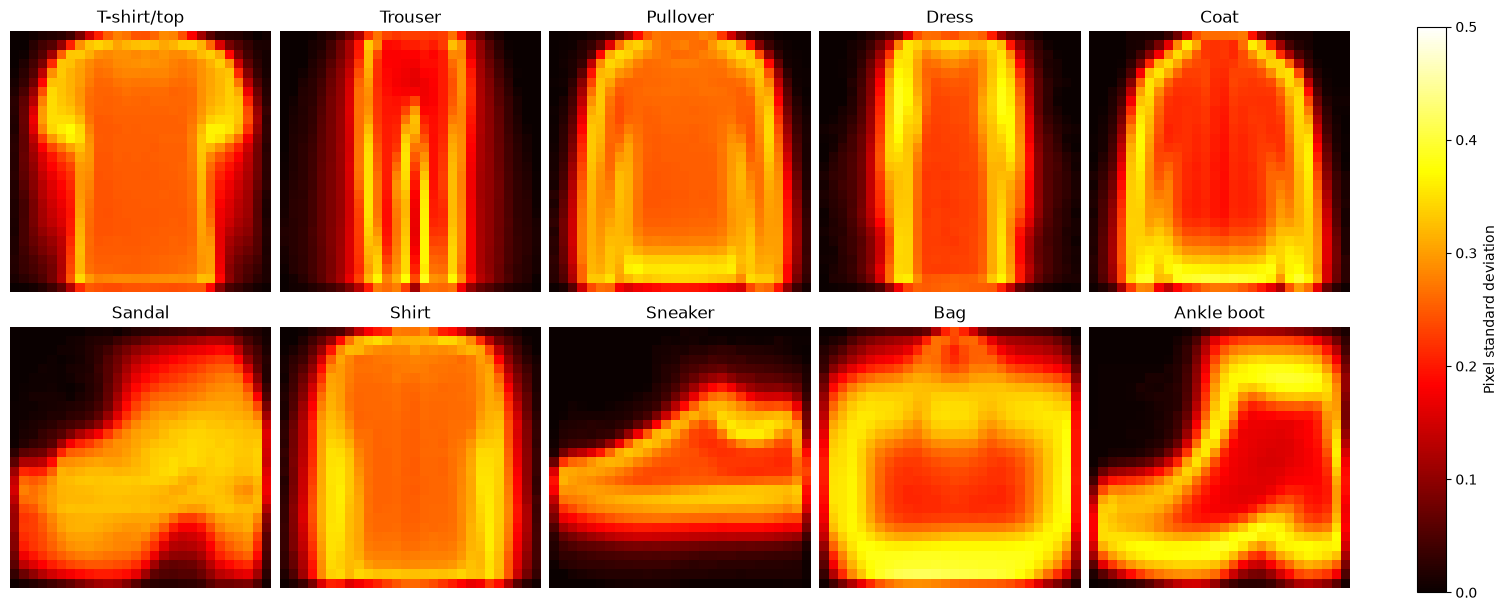

In [48]:
# 색상 히트맵으로 밝기 변화(Std)확인
# 검정 → 빨강 → 노랑 → 흰색으로 갈수록 사진마다 그 위치의 픽셀 밝기가 많이 다르다는 뜻
fig, axes = plt.subplots(
    2, 5, figsize=(15, 6), layout="constrained")

for ax, idx in zip(axes.flat, [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]):  # 5: Sandal, 8: Bag
    std_image = pixels[targets == idx].std(axis=0)

    heatmap = ax.imshow(
        std_image,
        cmap="hot",
        vmin=0,
        vmax=0.5
    )
    ax.set_title(train_dataset.classes[idx])
    ax.axis("off")

fig.colorbar(heatmap, ax=axes, label="Pixel standard deviation")
plt.show()

| 색상 | 의미 |
|---|---|
| 검정 | 사진마다 픽셀 값이 거의 같음 |
| 빨강 | 픽셀 값의 차이가 어느 정도 있음 |
| 노랑·흰색 | 픽셀 값의 차이가 큼 |

> 노랑과 흰색이 크게 보이는 클래스는 각 이미지가 다 다를 수 있다. 해당 클래스는 증강 시, 주의가 필요해보인다.

## 데이터 정제 및 레이블링 (Data Cleaning & Labeling)
- 목적: 정리되어 제공되는 데이터의 구조와 이미지, 정답 상태를 확인하고 학습에 필요한 전처리를 결정한다.
- EDA 시, 전처리가 필요할 만큼의 정제나 라벨 수정이 필요한 점을 발견하지 못해 기존 데이터 그대로 사용한다.
- 텐서 변환(모델이 잘 알아들을 수 있도록 변환시키기)과 정규화는 학습용 전처리 단계에서 진행한다.

# 실험 및 모델 학습관련 😊 공통 사용
> 추가 셀을 사용할 수 있으나 기존 셀을 활용하여 실시
> 
> 전처리에서는 download=True로 설정해서 설치 후, 실험이 가능하다.

## 학습용 전처리 및 데이터 구성
- 이미지 텐서 변환
- 출력 범위 맞추기(정규화)
- 전처리 실시
- 출력하여 확인하기(shape, type, min(), max())
- 데이터로더 구성
- 한 배치를 꺼내 이미지, 라벨의 shape 확인

In [14]:
# 이미지 텐서 변환
# 전처리 실시

import torchvision.transforms as transforms

# 데이터셋 및 DataLoader 설정
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))  # [-1, 1] 범위로 정규화
])

# EDA랑 분리하기 위해서 전처리용 prodessed로 데이터셋 객체 생성
train_processed = torchvision.datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform
)

test_processed = torchvision.datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform
)
# 샘플을 꺼내는 시점에서 전처리가 적용
image, label = train_processed[0]

# 전처리 결과 출력하여 확인하기(shape, type, min(), max())
print("이미지 shape:", image.shape)
print("이미지 자료형:", type(image))
print("텐서 데이터 타입:", image.dtype)
print("최솟값:", image.min().item())
print("최댓값:", image.max().item())
print("라벨:", label)


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.73MB/s]

이미지 shape: torch.Size([1, 28, 28])
이미지 자료형: <class 'torch.Tensor'>
텐서 데이터 타입: torch.float32
최솟값: -1.0
최댓값: 1.0
라벨: 9


In [15]:
# 데이터로더 구성
# 전처리가 연결된 데이터셋으로 DataLoader 구성
# batch_size=64는 임의로 설정한다.
# 추후에 하이퍼 파라미터설정 시, 실험을 통해 실시한다.
train_loader = torch.utils.data.DataLoader(
    train_processed, batch_size=64, shuffle=True
)
test_loader = torch.utils.data.DataLoader(
    test_processed, batch_size=64, shuffle=False
)

images, labels = next(iter(train_loader))

print("이미지 배치 shape:", images.shape)
print("라벨 배치 shape:", labels.shape)

이미지 배치 shape: torch.Size([64, 1, 28, 28])
라벨 배치 shape: torch.Size([64])


## 데이터셋 분할 
- 목적: 총 학습 데이터는 60,000장이며 EDA를 통해 클래스별 6,000장이 있는걸 확인했다. 이 안에서도 '홀드아웃'방식으로 나누어 검증 데이터를 확보한다.
- 테스트 데이터는 최종 평가용으로 유지한다.
- 학습데이터에서 80%는 학습으로 20%는 검증으로 분할한다.

In [16]:
import numpy as np
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

# 전체 이미지의 위치 번호
indices = np.arange(len(train_processed))

# 클래스 비율을 유지하며 80:20으로 분할
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42, # 같은 분할이 나오도록 고정
    stratify=train_processed.targets.numpy() # 클래스 비율을 유지
)

# 나눈 위치 번호로 학습·검증 데이터셋 구성
train_subset = Subset(train_processed, train_indices) # 이미지를 복사하지 않고, 선택한 위치의 데이터만 꺼내 쓰는 역할
val_subset = Subset(train_processed, val_indices)

print("학습 데이터:", len(train_subset))
print("검증 데이터:", len(val_subset))
print("테스트 데이터:", len(test_processed))

학습 데이터: 48000
검증 데이터: 12000
테스트 데이터: 10000


In [17]:
# 검증 데이터에 맞춰 데이터 로드 재작성
train_loader = torch.utils.data.DataLoader(
    train_subset, batch_size=64, shuffle=True
)

val_loader = torch.utils.data.DataLoader(
    val_subset, batch_size=64, shuffle=False
)

test_loader = torch.utils.data.DataLoader(
    test_processed, batch_size=64, shuffle=False
)

> 전체감의 계획을 보았다면 계속적으로 데이터 로더를 만드는 일이 줄어들거라 생각한다. 위의 로더 2개는 내 목표로 만들었으나 검증 데이터가 없다는 사실을 늦게 깨닳고 데이터 로더를 또다시 만들게되었다.

## cGAN 구조 확인 및 학습 방식 이해, 재현
- 목적: 베이스라인의 모델 구조를 이해하고 모델 성능 개선에 필요한 것을 사전에 확인한다.

In [5]:
import torch
import torch.nn as nn

image_size = 28      # Fashion MNIST 이미지 크기
num_classes = 10     # 10개 클래스
latent_dim = 100     # 잠재 공간 차원

# 생성자 (Generator)
class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()
        # 레이블 임베딩
        self.label_emb = nn.Embedding(num_classes, num_classes)

        self.init_size = image_size // 4  # 7

        self.l1 = nn.Sequential(
            nn.Linear(latent_dim + num_classes, 128 * self.init_size * self.init_size),
            nn.ReLU(inplace=True)
        )

        self.conv_blocks = nn.Sequential(
            nn.BatchNorm2d(128),
            nn.Upsample(scale_factor=2),  # 7 → 14
            nn.Conv2d(128, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64, 0.8),
            nn.ReLU(inplace=True),
            nn.Upsample(scale_factor=2),  # 14 → 28
            nn.Conv2d(64, 1, kernel_size=3, stride=1, padding=1),
            nn.Tanh()  # 출력 범위 [-1, 1]
        )

    def forward(self, noise, labels):
        label_input = self.label_emb(labels)
        gen_input = torch.cat((noise, label_input), -1)
        out = self.l1(gen_input)
        out = out.view(out.size(0), 128, self.init_size, self.init_size)
        img = self.conv_blocks(out)
        return img

# 판별자 (Discriminator)
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        # 레이블을 단일 채널 값으로 임베딩
        self.label_emb = nn.Embedding(num_classes, 1)

        self.model = nn.Sequential(
            # 이미지(1 채널)와 레이블(1 채널)을 채널 차원에서 결합하여 2채널로 입력
            nn.Conv2d(1 + 1, 64, kernel_size=3, stride=2, padding=1),  # 28 → 14
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),      # 14 → 7
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(),
            nn.Linear(128 * (image_size // 4) * (image_size // 4), 1),   # 128*7*7
            nn.Sigmoid()
        )

    def forward(self, img, labels):
        batch_size = img.size(0)
        label = self.label_emb(labels)
        label = label.view(batch_size, 1, 1, 1)
        label = label.expand(batch_size, 1, image_size, image_size)
        # 이미지와 레이블을 채널 차원에서 연결
        d_in = torch.cat((img, label), 1)
        validity = self.model(d_in)
        return validity

In [6]:
# 모델 초기화
generator = Generator().to(device)
discriminator = Discriminator().to(device)

epochs = 30
criterion = nn.BCELoss()
optimizer_G = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizer_D = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

NameError: name 'optim' is not defined

> 일하라 디코

In [71]:
%pip install --upgrade certifi

Note: you may need to restart the kernel to use updated packages.


In [77]:
# 디스코드 알림에 새로 필요한 라이브러리
import getpass
import urllib.request
import json
import urllib.error
import ssl
import certifi

ssl_context = ssl.create_default_context(cafile=certifi.where())

discord_webhook_url = getpass.getpass(
    "디스코드 웹훅 URL 입력: "
).strip()

def send_discord_alert(message):
    payload = json.dumps({
        "content": message,
        "allowed_mentions": {"parse": []}
    }).encode("utf-8")

    request = urllib.request.Request(
        discord_webhook_url,
        data=payload,
        headers={
            "Content-Type": "application/json",
            "User-Agent": "Mission8-Training-Notifier"
        },
        method="POST"
    )

    try:
        with urllib.request.urlopen(
    request, timeout=15, context=ssl_context
) as response:
              success = 200 <= response.status < 300        

        print("디스코드 알림 전송 완료" if success else "알림 전송 실패")
        return success


    except urllib.error.URLError as error:
        reason = error.reason

        print("연결 오류 종류:", type(reason).__name__)
        print("오류 번호:", getattr(reason, "errno", None))
        print("인증서 오류:", getattr(reason, "verify_message", None))
        return False

In [78]:
send_discord_alert("🔔 미션 9 학습 알림 연결 테스트!")

디스코드 알림 전송 완료


True

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Epoch 1/30: 100%|██████████| 750/750 [02:00<00:00,  6.24batch/s, D=0.8062, G=1.3782]


Epoch [1/30] D_loss: 0.8062 G_loss: 1.3782


Epoch 2/30: 100%|██████████| 750/750 [02:12<00:00,  5.65batch/s, D=0.8911, G=1.3030]


Epoch [2/30] D_loss: 0.8911 G_loss: 1.3030


Epoch 3/30: 100%|██████████| 750/750 [02:03<00:00,  6.08batch/s, D=0.9585, G=1.2584]


...

Epoch [8/30] D_loss: 1.0804 G_loss: 1.1435


Epoch 9/30: 100%|██████████| 750/750 [01:59<00:00,  6.29batch/s, D=1.0691, G=1.1597]


Epoch [9/30] D_loss: 1.0691 G_loss: 1.1597


Epoch 10/30: 100%|██████████| 750/750 [01:56<00:00,  6.41batch/s, D=1.0627, G=1.1747]


Epoch [10/30] D_loss: 1.0627 G_loss: 1.1747


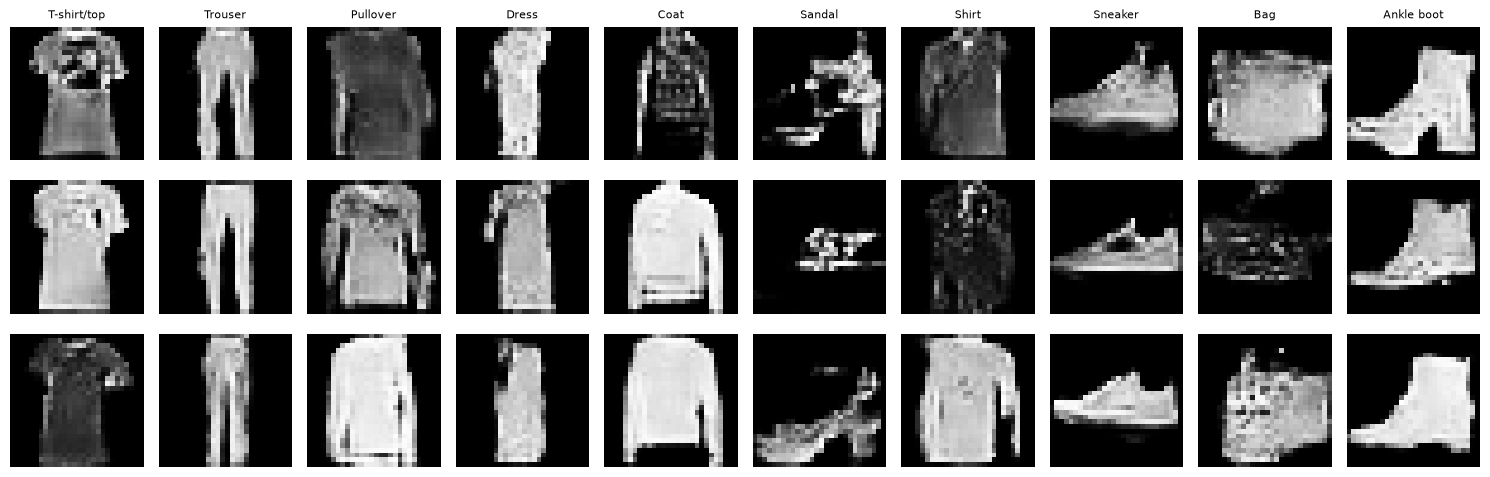

Epoch 11/30: 100%|██████████| 750/750 [01:57<00:00,  6.40batch/s, D=1.0643, G=1.1824]


Epoch [11/30] D_loss: 1.0643 G_loss: 1.1824


Epoch 12/30: 100%|██████████| 750/750 [01:57<00:00,  6.39batch/s, D=1.0667, G=1.1873]


Epoch [12/30] D_loss: 1.0667 G_loss: 1.1873


Epoch 13/30: 100%|██████████| 750/750 [01:56<00:00,  6.41batch/s, D=1.0632, G=1.1908]


...

Epoch [18/30] D_loss: 1.0573 G_loss: 1.2217


Epoch 19/30: 100%|██████████| 750/750 [02:14<00:00,  5.58batch/s, D=1.0423, G=1.2416]


Epoch [19/30] D_loss: 1.0423 G_loss: 1.2416


Epoch 20/30: 100%|██████████| 750/750 [02:18<00:00,  5.43batch/s, D=1.0288, G=1.2611]


Epoch [20/30] D_loss: 1.0288 G_loss: 1.2611


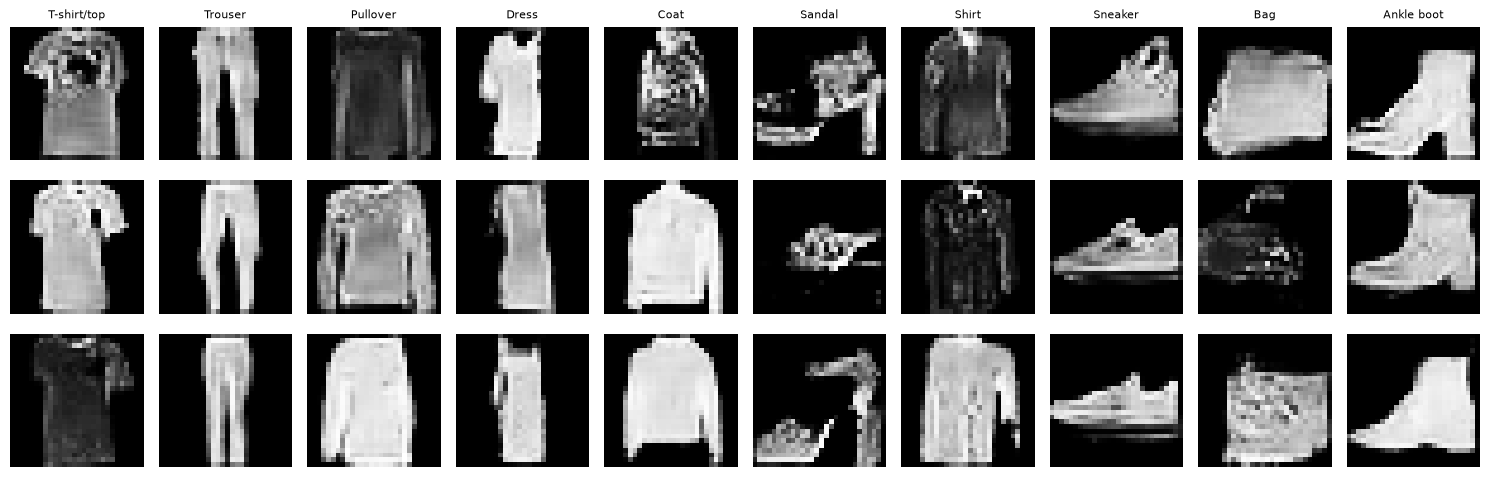

Epoch 21/30: 100%|██████████| 750/750 [02:21<00:00,  5.29batch/s, D=1.0191, G=1.2753]


Epoch [21/30] D_loss: 1.0191 G_loss: 1.2753


Epoch 22/30: 100%|██████████| 750/750 [02:09<00:00,  5.80batch/s, D=1.0240, G=1.2780]


Epoch [22/30] D_loss: 1.0240 G_loss: 1.2780


Epoch 23/30: 100%|██████████| 750/750 [02:02<00:00,  6.13batch/s, D=1.0275, G=1.2810]


...

Epoch [28/30] D_loss: 1.0197 G_loss: 1.2994


Epoch 29/30: 100%|██████████| 750/750 [02:10<00:00,  5.74batch/s, D=1.0241, G=1.3045]


Epoch [29/30] D_loss: 1.0241 G_loss: 1.3045


Epoch 30/30: 100%|██████████| 750/750 [02:21<00:00,  5.31batch/s, D=1.0244, G=1.3090]


Epoch [30/30] D_loss: 1.0244 G_loss: 1.3090


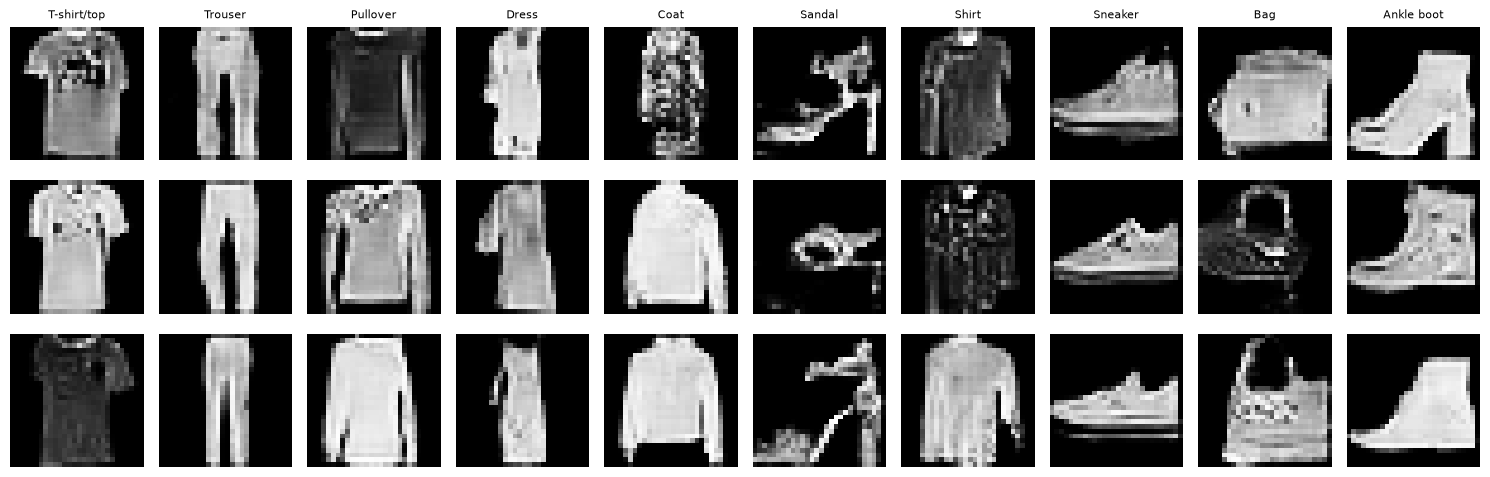

디스코드 알림 전송 완료


In [81]:
from pathlib import Path
from tqdm.auto import tqdm

# 같은 폴더에 체크포인트가 있으면 이어서 학습
save_dir = Path("./checkpoints/cgan_baseline")
save_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = save_dir / "last.pt"

start_epoch = 0
history = {"d_loss": [], "g_loss": []}

# 에포크별 이미지 비교를 위한 고정 노이즈와 라벨
fixed_noise = torch.randn(30, latent_dim, device=device)
fixed_labels = torch.arange(num_classes, device=device).repeat(3)

# 체크포인트 불러오기
if checkpoint_path.exists():
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    generator.load_state_dict(checkpoint["generator"])
    discriminator.load_state_dict(checkpoint["discriminator"])
    optimizer_G.load_state_dict(checkpoint["optimizer_G"])
    optimizer_D.load_state_dict(checkpoint["optimizer_D"])

    start_epoch = checkpoint["epoch"]
    history = checkpoint["history"]

    fixed_noise = checkpoint["fixed_noise"].to(device)
    fixed_labels = checkpoint["fixed_labels"].to(device)

    # 기본 DataLoader(shuffle=True)의 난수 상태도 함께 복원
    torch.set_rng_state(checkpoint["torch_rng_state"])

    if device.type == "cuda" and checkpoint["cuda_rng_states"]:
        torch.cuda.set_rng_state_all(checkpoint["cuda_rng_states"])

    print(f"{start_epoch}에포크 완료 상태에서 이어서 학습합니다.")

try:
    generator.train()
    discriminator.train()

    for epoch in range(start_epoch, epochs):
        d_loss_sum = 0.0
        g_loss_sum = 0.0
        sample_count = 0

        progress = tqdm(
            train_loader,
            desc=f"Epoch {epoch + 1}/{epochs}",
            unit="batch"
        )

        for imgs, labels in progress:
            imgs = imgs.to(device)
            labels = labels.to(device)
            batch_size_current = imgs.size(0)

            valid = torch.ones(batch_size_current, 1, device=device)
            fake = torch.zeros(batch_size_current, 1, device=device)

            # 판별자 학습
            optimizer_D.zero_grad()

            real_loss = criterion(discriminator(imgs, labels), valid)

            noise = torch.randn(
                batch_size_current, latent_dim, device=device
            )
            gen_imgs = generator(noise, labels)

            fake_loss = criterion(
                discriminator(gen_imgs.detach(), labels), fake
            )

            d_loss = real_loss + fake_loss
            d_loss.backward()
            optimizer_D.step()

            # 생성자 학습
            optimizer_G.zero_grad()

            g_loss = criterion(discriminator(gen_imgs, labels), valid)
            g_loss.backward()
            optimizer_G.step()

            # 배치 크기를 반영한 에포크 평균 계산
            d_loss_sum += d_loss.item() * batch_size_current
            g_loss_sum += g_loss.item() * batch_size_current
            sample_count += batch_size_current

            progress.set_postfix(
                D=f"{d_loss_sum / sample_count:.4f}",
                G=f"{g_loss_sum / sample_count:.4f}"
            )

        mean_d_loss = d_loss_sum / sample_count
        mean_g_loss = g_loss_sum / sample_count

        history["d_loss"].append(mean_d_loss)
        history["g_loss"].append(mean_g_loss)

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"D_loss: {mean_d_loss:.4f} "
            f"G_loss: {mean_g_loss:.4f}"
        )

        # 10에포크마다 같은 노이즈로 생성 결과 비교
        if (epoch + 1) % 10 == 0:
            generator.eval()

            with torch.no_grad():
                sample_imgs = generator(
                    fixed_noise, fixed_labels
                ).cpu()

            # [-1, 1] → [0, 1]로 복원하여 표시
            sample_imgs = (sample_imgs + 1) / 2

            fig, axs = plt.subplots(
                3, num_classes,
                figsize=(15, 5),
                squeeze=False
            )

            for row in range(3):
                for col in range(num_classes):
                    idx = row * num_classes + col
                    axs[row, col].imshow(
                        sample_imgs[idx, 0],
                        cmap="gray",
                        vmin=0,
                        vmax=1
                    )
                    axs[row, col].axis("off")

                    if row == 0:
                        axs[row, col].set_title(
                            train_processed.classes[col],
                            fontsize=8
                        )

            plt.tight_layout()
            plt.savefig(
                save_dir / f"samples_epoch_{epoch + 1:03d}.png",
                dpi=150,
                bbox_inches="tight"
            )
            plt.show()
            plt.close(fig)

            generator.train()

        # 매 에포크 완료 후 체크포인트 저장
        checkpoint = {
            "epoch": epoch + 1,
            "generator": generator.state_dict(),
            "discriminator": discriminator.state_dict(),
            "optimizer_G": optimizer_G.state_dict(),
            "optimizer_D": optimizer_D.state_dict(),
            "history": history,
            "fixed_noise": fixed_noise.cpu(),
            "fixed_labels": fixed_labels.cpu(),
            "torch_rng_state": torch.get_rng_state(),
            "cuda_rng_states": (
                torch.cuda.get_rng_state_all()
                if device.type == "cuda" else []
            ),
            "config": {
                "latent_dim": latent_dim,
                "num_classes": num_classes,
                "batch_size": train_loader.batch_size,
                "epochs": epochs
            }
        }
        # 임시 파일 저장이 끝난 뒤 기존 체크포인트 교체
        temporary_path = save_dir / "last.tmp"
        torch.save(checkpoint, temporary_path)
        temporary_path.replace(checkpoint_path)

except Exception:
    if "send_discord_alert" in globals():
        send_discord_alert(
            "⚠️ 미션 9 cGAN 학습 중 오류가 발생했어요. 노트북을 확인해 주세요."
        )
    raise

else:
    if "send_discord_alert" in globals():
        send_discord_alert(
            "✅ 미션 9 cGAN 학습 루프가 정상 종료됐어요!\n"
            "마지막 완료 에포크의 체크포인트를 확인해 주세요."
        )

## 모델 평가 및 검증
- 목적: 생성자가 라벨과 유사한 이미지를 생성하는지를 정성, 정량정보로 확인한다. 확인된 내용을 기반으로 성능 개선을 준비한다.
### 정성평가
- 생성 이미지를 클래스별로 print하여 확인한다.
- 실험마다 동일 노이즈와 레발로 생성 결과를 비교한다.

완료 에포크: 30
평가 장치: cpu


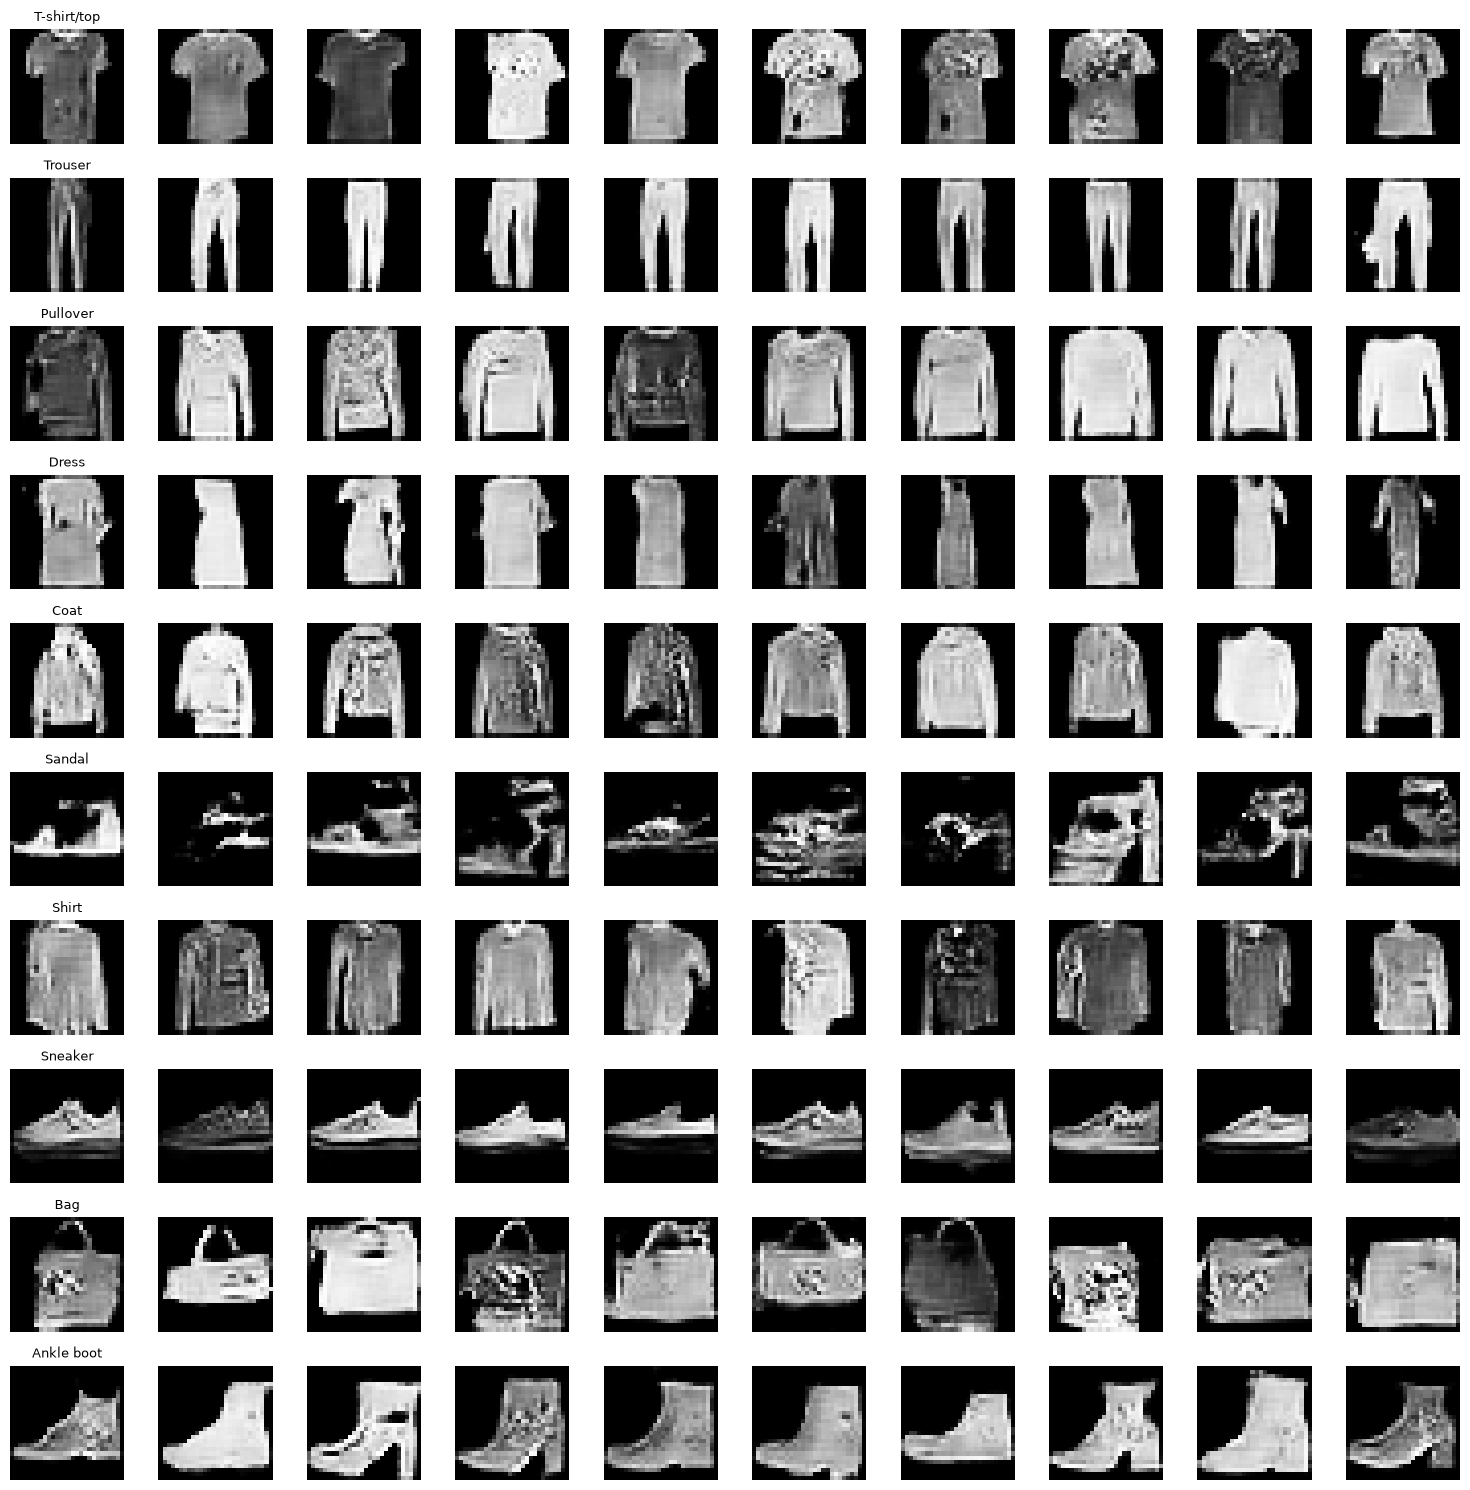

In [82]:
# 학습 완료 상태 확인
print("완료 에포크:", len(history["g_loss"]))
print("평가 장치:", device)

# 클래스별 10장씩 생성
generator.eval()

eval_rng = torch.Generator(device="cpu").manual_seed(42)

eval_noise = torch.randn(
    num_classes * 10,
    latent_dim,
    generator=eval_rng
).to(device)

eval_labels = torch.arange(
    num_classes, device=device
).repeat_interleave(10)

with torch.inference_mode():
    generated_images = generator(eval_noise, eval_labels).cpu()

# 시각화를 위해 [-1, 1] → [0, 1]
display_images = (generated_images + 1) / 2

fig, axes = plt.subplots(
    num_classes, 10,
    figsize=(15, 15)
)

for idx in range(num_classes):
    for col in range(10):
        image_idx = idx * 10 + col

        axes[idx, col].imshow(
            display_images[image_idx, 0],
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[idx, col].axis("off")

        if col == 0:
            axes[idx, col].set_title(
                train_processed.classes[idx],
                fontsize=9
            )

plt.tight_layout()
plt.show()

> 생성하는 것은 가능해보이나 이미자가 앵클부츠에 스니커즈가 섞여있는것 처럼 보이거나 상의들은 한쪽의 팔이 없거나 일부가 탈락된 것처럼 보인다.

### 정량평가 - 분류기 활용
- 별도로 학습한 FashionMNIST 분류기가 생성 이미지의 클래스를 예측한다.
- 혼동행렬과 전체·클래스별 라벨 일치율을 기록한다.
- 분류기도 틀릴 수 있으므로 이미지 시각화와 함께 해석한다.

In [83]:
# CE를 사용하나 Softmax는 사용하지 않는다.
import torch
import torch.nn as nn
from pathlib import Path
from tqdm.auto import tqdm

class FashionClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 28 → 14

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 14 → 7
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, images):
        return self.classifier(self.features(images))


fashion_classifier = FashionClassifier().to(device)

classifier_criterion = nn.CrossEntropyLoss()
classifier_optimizer = torch.optim.Adam(
    fashion_classifier.parameters(),
    lr=0.001
)

classifier_dir = Path("./checkpoints/fashion_classifier")
classifier_dir.mkdir(parents=True, exist_ok=True)
classifier_path = classifier_dir / "best.pt"

In [84]:
# 학습·검증하고 가장 좋은 분류기 저장
classifier_epochs = 10
best_val_accuracy = -1.0
classifier_history = []

for epoch in range(classifier_epochs):
    # 학습
    fashion_classifier.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_count = 0

    for images, labels in tqdm(
        train_loader,
        desc=f"분류기 {epoch + 1}/{classifier_epochs} 학습"
    ):
        images = images.to(device)
        labels = labels.to(device)

        classifier_optimizer.zero_grad()

        outputs = fashion_classifier(images)
        loss = classifier_criterion(outputs, labels)

        loss.backward()
        classifier_optimizer.step()

        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_count += batch_size

    # 검증: 가중치를 업데이트하지 않음
    fashion_classifier.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_count = 0

    with torch.inference_mode():
        for images, labels in tqdm(
            val_loader,
            desc=f"분류기 {epoch + 1}/{classifier_epochs} 검증"
        ):
            images = images.to(device)
            labels = labels.to(device)

            outputs = fashion_classifier(images)
            loss = classifier_criterion(outputs, labels)

            batch_size = labels.size(0)
            val_loss_sum += loss.item() * batch_size
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            val_count += batch_size

    train_loss = train_loss_sum / train_count
    val_loss = val_loss_sum / val_count
    train_accuracy = train_correct / train_count
    val_accuracy = val_correct / val_count

    classifier_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy
    })

    print(
        f"Epoch {epoch + 1}/{classifier_epochs} | "
        f"학습 정확도: {train_accuracy:.2%} | "
        f"검증 정확도: {val_accuracy:.2%} | "
        f"검증 손실: {val_loss:.4f}"
    )

    # 검증 정확도가 가장 높은 모델 저장
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save({
            "model": fashion_classifier.state_dict(),
            "epoch": epoch + 1,
            "val_accuracy": val_accuracy,
            "classes": train_processed.classes,
            "normalization": {
                "mean": [0.5],
                "std": [0.5]
            }
        }, classifier_path)

# 최고 검증 정확도의 분류기를 불러와 평가용으로 고정
classifier_checkpoint = torch.load(
    classifier_path,
    map_location="cpu",
    weights_only=True
)

fashion_classifier.load_state_dict(
    classifier_checkpoint["model"]
)
fashion_classifier.eval()
fashion_classifier.requires_grad_(False)

print(
    f"\n선택한 분류기: {classifier_checkpoint['epoch']}에포크"
    f"\n검증 정확도: {classifier_checkpoint['val_accuracy']:.2%}"
)

분류기 1/10 검증: 100%|██████████| 188/188 [00:01<00:00, 106.24it/s]


Epoch 1/10 | 학습 정확도: 81.40% | 검증 정확도: 88.31% | 검증 손실: 0.3162


분류기 2/10 검증: 100%|██████████| 188/188 [00:01<00:00, 129.64it/s]


Epoch 2/10 | 학습 정확도: 87.75% | 검증 정확도: 90.04% | 검증 손실: 0.2707


분류기 3/10 검증: 100%|██████████| 188/188 [00:01<00:00, 133.57it/s]


...

Epoch 8/10 | 학습 정확도: 93.65% | 검증 정확도: 92.25% | 검증 손실: 0.2170


분류기 9/10 검증: 100%|██████████| 188/188 [00:02<00:00, 85.90it/s]


Epoch 9/10 | 학습 정확도: 94.20% | 검증 정확도: 92.62% | 검증 손실: 0.2104


분류기 10/10 검증: 100%|██████████| 188/188 [00:01<00:00, 96.02it/s] 


Epoch 10/10 | 학습 정확도: 94.69% | 검증 정확도: 92.62% | 검증 손실: 0.2220

선택한 분류기: 9에포크
검증 정확도: 92.62%


분류기 검증 결과 수집: 100%|██████████| 188/188 [00:01<00:00, 115.40it/s]


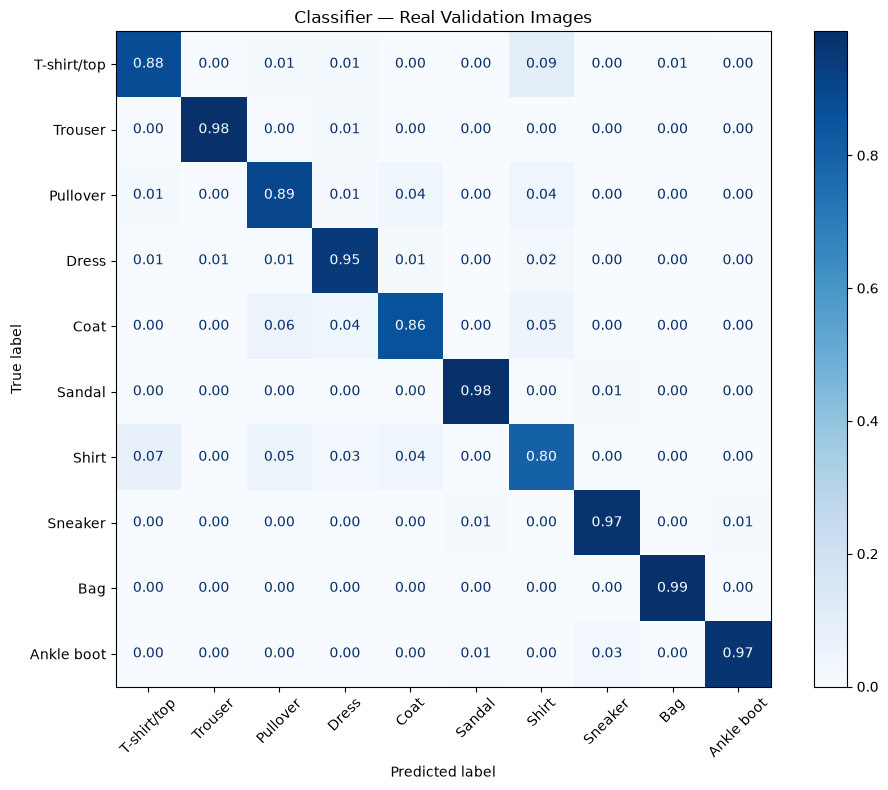

              precision    recall  f1-score   support

 T-shirt/top      0.901     0.875     0.888      1200
     Trouser      0.991     0.980     0.985      1200
    Pullover      0.874     0.894     0.884      1200
       Dress      0.900     0.948     0.923      1200
        Coat      0.899     0.857     0.878      1200
      Sandal      0.982     0.982     0.982      1200
       Shirt      0.792     0.798     0.795      1200
     Sneaker      0.957     0.975     0.966      1200
         Bag      0.985     0.987     0.986      1200
  Ankle boot      0.985     0.967     0.976      1200

    accuracy                          0.926     12000
   macro avg      0.926     0.926     0.926     12000
weighted avg      0.926     0.926     0.926     12000



In [85]:
# 혼동행렬 확인하기
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report
)

true_labels = []
predicted_labels = []

fashion_classifier.eval()

with torch.inference_mode():
    for images, labels in tqdm(
        val_loader, desc="분류기 검증 결과 수집"
    ):
        outputs = fashion_classifier(images.to(device))
        predictions = outputs.argmax(dim=1).cpu()

        true_labels.extend(labels.cpu().tolist())
        predicted_labels.extend(predictions.tolist())

class_names = train_processed.classes

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    true_labels,
    predicted_labels,
    labels=list(range(num_classes)),
    display_labels=class_names,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Classifier — Real Validation Images")
plt.tight_layout()
plt.show()

print(classification_report(
    true_labels,
    predicted_labels,
    labels=list(range(num_classes)),
    target_names=class_names,
    digits=3,
    zero_division=0
))

> 실제 검증 이미지에서 티셔츠를 셔츠로 약 9%, 셔츠를  티셔츠로 약 7%, 코트를 티셔츠로 약 6%를 오분류했다.
>
> 일단 티셔츠와 셔츠가 가장 크게 오분류되고 있어 생성 이미지 평가에서도 분류기의 이러한 한계를 함께 고려한다.

생성 이미지 라벨 평가: 100%|██████████| 50/50 [00:01<00:00, 32.44it/s]


전체 라벨 일치율: 93.42%

클래스별 라벨 일치율
T-shirt/top: 88.20%
Trouser: 100.00%
Pullover: 95.40%
Dress: 97.00%
Coat: 76.00%
Sandal: 98.60%
Shirt: 83.00%
Sneaker: 98.60%
Bag: 98.60%
Ankle boot: 98.80%


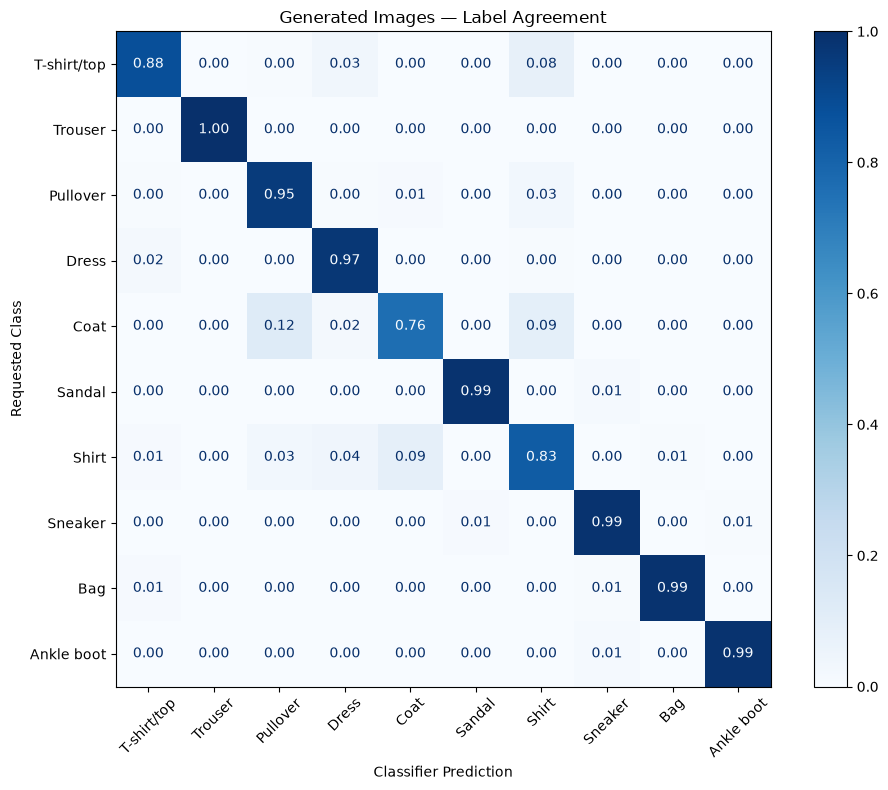

In [86]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

samples_per_class = 500
eval_batch_size = 100

# 만들어 달라고 할 클래스: 클래스별 500개
requested_labels = torch.arange(num_classes).repeat_interleave(
    samples_per_class
)

# 실험마다 동일한 노이즈 사용
eval_rng = torch.Generator(device="cpu").manual_seed(42)

eval_noise = torch.randn(
    len(requested_labels),
    latent_dim,
    generator=eval_rng
)

predicted_labels = []

generator.eval()
fashion_classifier.eval()

with torch.inference_mode():
    for start in tqdm(
        range(0, len(requested_labels), eval_batch_size),
        desc="생성 이미지 라벨 평가"
    ):
        end = start + eval_batch_size

        noise_batch = eval_noise[start:end].to(device)
        label_batch = requested_labels[start:end].to(device)

        # 요청한 클래스의 이미지 생성
        generated = generator(noise_batch, label_batch)

        # 분류기가 판단한 클래스
        outputs = fashion_classifier(generated)
        predictions = outputs.argmax(dim=1).cpu().tolist()

        predicted_labels.extend(predictions)

requested = requested_labels.numpy()
predicted = np.array(predicted_labels)

# 전체 라벨 일치율
agreement = accuracy_score(requested, predicted)
print(f"전체 라벨 일치율: {agreement:.2%}")

# 클래스별 라벨 일치율
counts = confusion_matrix(
    requested,
    predicted,
    labels=list(range(num_classes))
)

class_agreement = counts.diagonal() / counts.sum(axis=1)

print("\n클래스별 라벨 일치율")
for name, score in zip(
    train_processed.classes, class_agreement
):
    print(f"{name}: {score:.2%}")

# 혼동행렬
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    requested,
    predicted,
    labels=list(range(num_classes)),
    display_labels=train_processed.classes,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Generated Images — Label Agreement")
ax.set_xlabel("Classifier Prediction")
ax.set_ylabel("Requested Class")

plt.tight_layout()
plt.show()

> 생성 이미지의 라벨 일치율은 코트가 76%로 가장 낮았다.
> 
> 코트를 풀오버로 약 1.2%, 셔츠로 9% 분류되어 클래스 간 특징 구분이 보족할 가능성이 있다.
> 
> 상기 내용을 시각화해서 한번 더 확인한다.
> 
> 0.99이상으로 분류한 것들은 너무 높은 수치임으로 의심해본다. (바지나 가방, 신발)

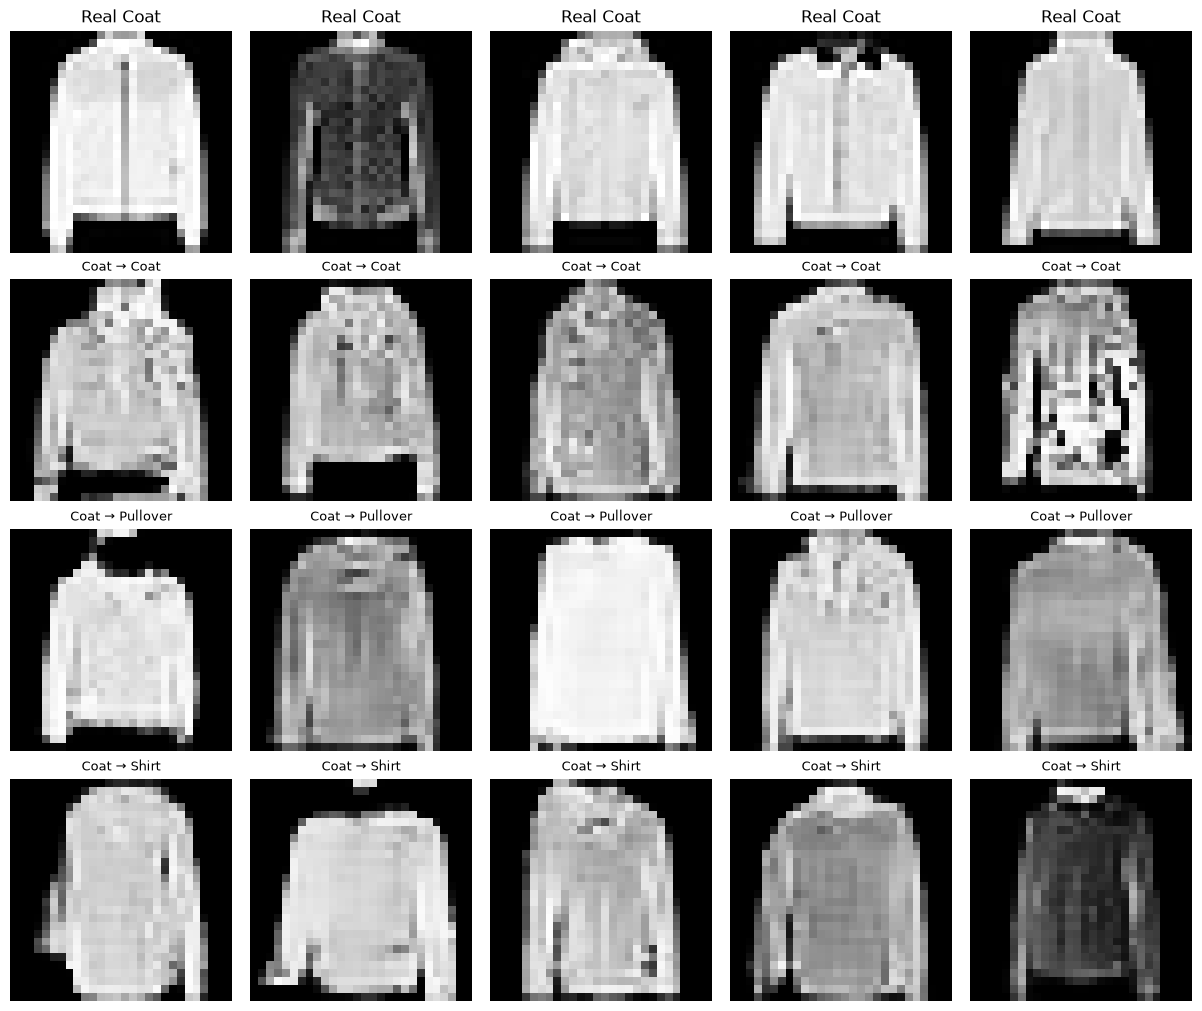

In [88]:
# 실제 코트 / 생성 코트 중 ‘코트’로 분류된 것 / ‘풀오버’로 분류된 것 / ‘셔츠’로 분류된 것

# 코트 500장 생성 후 분류
coat_id = train_processed.class_to_idx["Coat"]
rng = torch.Generator(device="cpu").manual_seed(42)

noise = torch.randn(500, latent_dim, generator=rng)
coat_labels = torch.full((500,), coat_id, dtype=torch.long)

coat_images = []
coat_predictions = []

generator.eval()
fashion_classifier.eval()

with torch.inference_mode():
    for start in range(0, 500, 100):
        generated = generator(
            noise[start:start + 100].to(device),
            coat_labels[start:start + 100].to(device)
        )

        predictions = fashion_classifier(generated).argmax(dim=1)

        coat_images.append(generated.cpu())
        coat_predictions.append(predictions.cpu())

coat_images = torch.cat(coat_images)
coat_predictions = torch.cat(coat_predictions)

# 표시할 때만 [-1, 1] → [0, 1]
coat_display = (coat_images + 1) / 2

# 실제 코트 샘플 선택
sample_rng = np.random.default_rng(42)
real_indices = sample_rng.choice(
    np.flatnonzero(targets == coat_id),
    size=5,
    replace=False
)

fig, axes = plt.subplots(
    4, 5,
    figsize=(12, 10),
    layout="constrained"
)

# 첫 행: 실제 코트
for col, image_idx in enumerate(real_indices):
    axes[0, col].imshow(
        pixels[image_idx], cmap="gray", vmin=0, vmax=1
    )
    axes[0, col].set_title("Real Coat")

# 나머지 행: 분류기 판단별 생성 코트
for row, predicted_name in enumerate(
    ["Coat", "Pullover", "Shirt"], start=1
):
    predicted_id = train_processed.class_to_idx[predicted_name]

    matching_indices = (
        (coat_predictions == predicted_id)
        .nonzero()
        .flatten()
        .numpy()
    )

    selected = sample_rng.choice(
        matching_indices,
        size=min(5, len(matching_indices)),
        replace=False
    )

    for col in range(5):
        ax = axes[row, col]

        if col < len(selected):
            image_idx = int(selected[col])
            ax.imshow(
                coat_display[image_idx, 0],
                cmap="gray", vmin=0, vmax=1
            )
            ax.set_title(f"Coat → {predicted_name}", fontsize=9)
        else:
            ax.text(
                0.5, 0.5, "No sample",
                ha="center", va="center",
                transform=ax.transAxes
            )

for ax in axes.flat:
    ax.axis("off")

plt.show()


> 전반적으로 윤곽은 보이나 디테일이 없다. 소매라던가 후드의 표현같이 특징이 보이지 않는다.

### 정량평가 - FID, IS
- FID: 실제 이미지와 생성 이미지의 특징 분포 차이를 확인한다.
  낮을수록 두 분포가 가깝다고 해석한다.
- IS: 생성 이미지의 분류 예측 확신도와
  전체 예측 클래스의 다양성을 확인한다. 높을수록 좋다.
- 두 지표는 FashionMNIST에 적용할 때의 한계를 고려하여 해석한다.
- 실험마다 평가 조건을 동일하게 유지하며,
  FID의 실제 이미지 기준으로 검증 데이터를 사용한다.

In [91]:
import os
import ssl
import certifi

os.environ["SSL_CERT_FILE"] = certifi.where()

# 인증서 파일이 정상적으로 로드되는지 확인
context = ssl.create_default_context()
print("로드된 인증서:", context.cert_store_stats())

로드된 인증서: {'x509': 117, 'crl': 0, 'x509_ca': 117}


In [92]:
# 사용전 설치
%pip install torchmetrics torch-fidelity

Note: you may need to restart the kernel to use updated packages.


In [95]:
import ssl
import certifi
import urllib.request
import shutil
from pathlib import Path

url = (
    "https://github.com/toshas/torch-fidelity/releases/download/"
    "v0.2.0/weights-inception-2015-12-05-6726825d.pth"
)

cache_dir = Path(torch.hub.get_dir()) / "checkpoints"
cache_dir.mkdir(parents=True, exist_ok=True)

weight_path = cache_dir / "weights-inception-2015-12-05-6726825d.pth"
temporary_path = weight_path.with_suffix(".download")

context = ssl.create_default_context(cafile=certifi.where())

with urllib.request.urlopen(
    url, context=context, timeout=60
) as response:
    with temporary_path.open("wb") as output:
        shutil.copyfileobj(response, output)

temporary_path.replace(weight_path)
print("다운로드 완료:", weight_path)

다운로드 완료: /Users/codeit/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth


In [96]:
from torchmetrics.image.fid import FrechetInceptionDistance
from torchmetrics.image.inception import InceptionScore

# 평가 도구는 CPU에서 계산
fid_metric = FrechetInceptionDistance(
    feature=2048,
    normalize=False
).cpu()

# FID 통계 계산의 수치 안정성을 위해 사용
fid_metric.set_dtype(torch.float64)

is_metric = InceptionScore(
    normalize=False,
    splits=10
).cpu()


def prepare_inception_input(images):
    # [-1, 1] → [0, 1]
    images = ((images.detach().cpu() + 1) / 2).clamp(0, 1)

    # 흑백 1채널 → 동일한 값을 가진 3채널
    images = images.repeat(1, 3, 1, 1)

    # [0, 1] 실수 → [0, 255] 정수
    return (images * 255).round().to(torch.uint8)


# 1. FID의 기준이 될 실제 검증 이미지
for images, _ in tqdm(
    val_loader,
    desc="FID: 실제 검증 이미지"
):
    fid_metric.update(
        prepare_inception_input(images),
        real=True
    )


# 2. 클래스별 500장씩 생성
samples_per_class = 500
metric_batch_size = 64

metric_labels = torch.arange(
    num_classes
).repeat_interleave(samples_per_class)

metric_rng = torch.Generator(device="cpu").manual_seed(42)

metric_noise = torch.randn(
    len(metric_labels),
    latent_dim,
    generator=metric_rng
)

# IS 계산 묶음에 클래스가 섞이도록 순서를 고정해서 섞기
order = torch.randperm(
    len(metric_labels),
    generator=metric_rng
)
metric_labels = metric_labels[order]
metric_noise = metric_noise[order]

generator.eval()

with torch.inference_mode():
    for start in tqdm(
        range(0, len(metric_labels), metric_batch_size),
        desc="FID·IS: 생성 이미지"
    ):
        end = start + metric_batch_size

        generated = generator(
            metric_noise[start:end].to(device),
            metric_labels[start:end].to(device)
        )

        prepared = prepare_inception_input(generated)

        fid_metric.update(prepared, real=False)
        is_metric.update(prepared)


# 3. 결과 계산
# IS 내부의 무작위 분할을 재현하기 위해 난수 상태를 잠시 고정
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(42)

    fid_value = fid_metric.compute().item()
    is_mean, is_std = is_metric.compute()

print(f"실제 검증 이미지 수: {len(val_loader.dataset)}")
print(f"생성 이미지 수: {len(metric_labels)}")
print(f"FID: {fid_value:.4f}")
print(f"IS: {is_mean.item():.4f} ± {is_std.item():.4f}")

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `InceptionScore` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)
FID·IS: 생성 이미지: 100%|██████████| 79/79 [1:57:35<00:00, 89.31s/it]    


실제 검증 이미지 수: 12000
생성 이미지 수: 5000
FID: 22.9728
IS: 3.8798 ± 0.1338


| 항목 | 베이스라인 결과 |
|---|---:|
| 실제 검증 이미지 | 12,000장 |
| 생성 이미지 | 5,000장 |
| **FID ↓** | **22.9728** |
| **IS ↑** | **3.8798 ± 0.1338** |
> 12,000 실제 검증 이미지 수 중 5,000장의 생성 이미지를 확인했다.
> 읽기가 어려워 Ai의 도움을 받았다.
> 베이스라인은 FID 22.9728, IS 3.8798 ± 0.1338을 기록했다.
> 이후 실험에서도 평가 모델, 전처리, 이미지 수와 생성 조건을 동일하게 유지하여 비교한다.
> ImageNet 기반 평가 모델과 FashionMNIST의 특성 차이를 고려하여, 시각화 및 클래스별 라벨 일치율과 함께 해석한다.
> 계산에 약 2시간 49분 걸렸으니, 다음 실험부터는 실제 검증 이미지의 FID 통계를 저장해 재사용하도록 바꾸는 게 좋을것 같다. 같은 기준 데이터라 매번 51분씩 다시 계산할 필요는 없도록 저장해 재사용을 한다.

> 아직 햇갈려서 FID, IS에 대해서 조금 적어두겠다.

| 평가 | 쉬운 질문 |
|---|---|
| **라벨 일치율** | “코트 만들어 달랬는데 코트가 나왔어?” |
| **FID ↓** | “만든 이미지 묶음이 실제 이미지 묶음과 비슷해?” |
| **IS ↑** | “분류기가 확신 있게 구분하고, 전체적으로 여러 종류라고 판단해?” |
| **눈으로 확인** | “소매가 빠지거나 이상한 무늬는 없어? 같은 모양만 반복해?” |

- FID 22.9728 -> 다음 모델에서 더 낮아지는가?
- IS 3.8798 -> 다음 모델에서 더 높아지는가?
이전 미션에서 기준선에 대해서 확인하는 부분이 있었다. 그것과 동일하게 **베이스라인 점수**라고 생각하면 된다. 

## 모델 학습 및 하이퍼파라미터 튜닝 (Model Training & Tuning)
- 목적: 베이스 라인모델의 성능 개선을 위해 필요한 실험을 실시한다.
- tqdm, 체크포인트 저장, 디스코드 알람을 기본으로 한다.
- 학습 에포크에 따른 변화비교를 하므로 Early Stopping은 사용하지 않는다.
- 평가용 분류기, 검증 데이터, 평가 이미지 수, 고정 노이즈와 라벨은 동일하게 유지한다.

In [2]:
# mps -> gpu로 옮겨야해서 재확인 및 구글에 저장
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

### 실험 1: 배치 크기에 따른 생성 결과 비교
기준 64, 비교 후보 32, 128
- 상기 기본 설정내용과 학습 에폭 수는 동일하게 유지한다.(배치 크기 64일때 30번 실시)
- 각 배치 사이즈마다 변수를 지정해서 불러오기 용이하도록 한다.
- 각 실험은 모델과 optimizer를 새로 초기화하여 시작한다.
- 같은 에폭이라도 업데이트 횟수가 달라짐을 고려하여 평가지표와 학습시간을 비교한다.

In [3]:
# 사전 준비: Generator, Discriminator, train_subset, train_processed,
# device, latent_dim, num_classes를 기존 노트북에서 정의해야 합니다.
import time
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm


def run_batch_experiment(batch_size, epochs=30,
                         output_root="./checkpoints/batch_experiments",
                         seed=42):
    """기존 베이스라인과 분리하여 한 배치 크기 실험을 실행·재개합니다."""
    torch.manual_seed(seed)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(seed)
    elif device.type == "mps":
        torch.mps.manual_seed(seed)

    # CPU에서 같은 초기 가중치를 만든 뒤 학습 장치로 이동
    generator = Generator().to(device)
    discriminator = Discriminator().to(device)
    criterion = torch.nn.BCELoss()
    optimizer_G = torch.optim.Adam(
        generator.parameters(), lr=0.0002, betas=(0.5, 0.999)
    )
    optimizer_D = torch.optim.Adam(
        discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999)
    )

    shuffle_rng = torch.Generator().manual_seed(seed)
    train_loader = torch.utils.data.DataLoader(
        train_subset, batch_size=batch_size, shuffle=True,
        generator=shuffle_rng, num_workers=0
    )
    split_indices = torch.as_tensor(train_subset.indices, dtype=torch.long)
    config = {
        "batch_size": batch_size, "latent_dim": latent_dim,
        "num_classes": num_classes, "seed": seed,
        "lr": 0.0002, "betas": [0.5, 0.999]
    }

    def synchronize_device():
        if device.type == "cuda":
            torch.cuda.synchronize()
        elif device.type == "mps":
            torch.mps.synchronize()

    def notify(message):
        # 알림 실패가 학습 결과 저장을 방해하지 않도록 처리
        try:
            if "send_discord_alert" in globals():
                send_discord_alert(message)
        except Exception as error:
            print("알림 오류:", type(error).__name__)

    # 같은 폴더에 체크포인트가 있으면 이어서 학습
    save_dir = Path(output_root) / f"batch_{batch_size}"
    save_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = save_dir / "last.pt"

    start_epoch = 0
    history = {"d_loss": [], "g_loss": [], "epoch_seconds": []}

    # 에포크별 이미지 비교를 위한 고정 노이즈와 라벨
    fixed_noise = torch.randn(3 * num_classes, latent_dim, generator=torch.Generator().manual_seed(42)).to(device)
    fixed_labels = torch.arange(num_classes, device=device).repeat(3)

    # 체크포인트 불러오기
    if checkpoint_path.exists():
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        if checkpoint["config"] != config:
            raise ValueError("저장된 설정과 다릅니다. 별도 저장 폴더를 지정하세요.")
        if not torch.equal(checkpoint["train_indices"], split_indices):
            raise ValueError("학습·검증 분할이 이전 실험과 다릅니다.")
        generator.load_state_dict(checkpoint["generator"])
        discriminator.load_state_dict(checkpoint["discriminator"])
        optimizer_G.load_state_dict(checkpoint["optimizer_G"])
        optimizer_D.load_state_dict(checkpoint["optimizer_D"])

        start_epoch = checkpoint["epoch"]
        history = checkpoint["history"]

        fixed_noise = checkpoint["fixed_noise"].to(device)
        fixed_labels = checkpoint["fixed_labels"].to(device)

        shuffle_rng.set_state(checkpoint["shuffle_rng_state"])

        # 난수 상태 복원
        torch.set_rng_state(checkpoint["torch_rng_state"])

        if device.type == "cuda" and checkpoint["cuda_rng_states"]:
            torch.cuda.set_rng_state_all(checkpoint["cuda_rng_states"])

        if device.type == "mps" and checkpoint.get("mps_rng_state") is not None:
            torch.mps.set_rng_state(checkpoint["mps_rng_state"])

        print(f"{start_epoch}에포크 완료 상태에서 이어서 학습합니다.")

    try:
        generator.train()
        discriminator.train()

        for epoch in range(start_epoch, epochs):
            synchronize_device()
            epoch_started = time.perf_counter()
            d_loss_sum = 0.0
            g_loss_sum = 0.0
            sample_count = 0

            progress = tqdm(
                train_loader,
                desc=f"Batch {batch_size} | Epoch {epoch + 1}/{epochs}",
                unit="batch"
            )

            for imgs, labels in progress:
                imgs = imgs.to(device)
                labels = labels.to(device)
                batch_size_current = imgs.size(0)

                valid = torch.ones(batch_size_current, 1, device=device)
                fake = torch.zeros(batch_size_current, 1, device=device)

                # 판별자 학습
                optimizer_D.zero_grad()

                real_loss = criterion(discriminator(imgs, labels), valid)

                noise = torch.randn(
                    batch_size_current, latent_dim, device=device
                )
                gen_imgs = generator(noise, labels)

                fake_loss = criterion(
                    discriminator(gen_imgs.detach(), labels), fake
                )

                d_loss = real_loss + fake_loss
                d_loss.backward()
                optimizer_D.step()

                # 생성자 학습
                optimizer_G.zero_grad()

                g_loss = criterion(discriminator(gen_imgs, labels), valid)
                g_loss.backward()
                optimizer_G.step()

                # 배치 크기를 반영한 에포크 평균 계산
                d_loss_sum += d_loss.item() * batch_size_current
                g_loss_sum += g_loss.item() * batch_size_current
                sample_count += batch_size_current

                progress.set_postfix(
                    D=f"{d_loss_sum / sample_count:.4f}",
                    G=f"{g_loss_sum / sample_count:.4f}"
                )

            mean_d_loss = d_loss_sum / sample_count
            mean_g_loss = g_loss_sum / sample_count

            synchronize_device()
            history["epoch_seconds"].append(time.perf_counter() - epoch_started)
            history["d_loss"].append(mean_d_loss)
            history["g_loss"].append(mean_g_loss)

            print(
                f"Epoch [{epoch + 1}/{epochs}] "
                f"D_loss: {mean_d_loss:.4f} "
                f"G_loss: {mean_g_loss:.4f}"
            )

            # 10에포크마다 같은 노이즈로 생성 결과 비교
            if (epoch + 1) % 10 == 0:
                generator.eval()

                with torch.no_grad():
                    sample_imgs = generator(
                        fixed_noise, fixed_labels
                    ).cpu()

                # [-1, 1] → [0, 1]로 복원하여 표시
                sample_imgs = (sample_imgs + 1) / 2

                fig, axs = plt.subplots(
                    3, num_classes,
                    figsize=(15, 5),
                    squeeze=False
                )

                for row in range(3):
                    for col in range(num_classes):
                        idx = row * num_classes + col
                        axs[row, col].imshow(
                            sample_imgs[idx, 0],
                            cmap="gray",
                            vmin=0,
                            vmax=1
                        )
                        axs[row, col].axis("off")

                        if row == 0:
                            axs[row, col].set_title(
                                train_processed.classes[col],
                                fontsize=8
                            )

                plt.tight_layout()
                plt.savefig(
                    save_dir / f"samples_epoch_{epoch + 1:03d}.png",
                    dpi=150,
                    bbox_inches="tight"
                )
                plt.show()
                plt.close(fig)

                generator.train()

            # 매 에포크 완료 후 체크포인트 저장
            checkpoint = {
                "epoch": epoch + 1,
                "generator": generator.state_dict(),
                "discriminator": discriminator.state_dict(),
                "optimizer_G": optimizer_G.state_dict(),
                "optimizer_D": optimizer_D.state_dict(),
                "history": history,
                "fixed_noise": fixed_noise.cpu(),
                "fixed_labels": fixed_labels.cpu(),
                "torch_rng_state": torch.get_rng_state(),
                "cuda_rng_states": (
                    torch.cuda.get_rng_state_all()
                    if device.type == "cuda" else []
                ),
                "config": config,
                "train_indices": split_indices,
                "shuffle_rng_state": shuffle_rng.get_state(),
                "mps_rng_state": (
                    torch.mps.get_rng_state() if device.type == "mps" else None
                ),
                "device": str(device),
                "torch_version": str(torch.__version__)
            }
            # 임시 파일 저장이 끝난 뒤 기존 체크포인트 교체
            temporary_path = save_dir / "last.tmp"
            torch.save(checkpoint, temporary_path)
            temporary_path.replace(checkpoint_path)

    except Exception:
        if "send_discord_alert" in globals():
            notify(
                f"⚠️ 미션 9 배치 {batch_size} 학습 오류. 노트북을 확인해 주세요."
            )
        raise

    else:
        if "send_discord_alert" in globals():
            notify(
                f"✅ 미션 9 배치 {batch_size}: {epochs}에포크 완료!\n"
                "마지막 완료 에포크의 체크포인트를 확인해 주세요."
            )

    generator.eval()
    print(f"체크포인트: {checkpoint_path}")
    print(f"누적 학습 시간(시각화·저장 제외): {sum(history['epoch_seconds']) / 60:.1f}분")
    return generator, history, checkpoint_path


Batch 32 | Epoch 1/30:   0%|          | 0/1500 [00:00<?, ?batch/s]

Epoch [1/30] D_loss: 0.5851 G_loss: 1.8269


Batch 32 | Epoch 2/30:   0%|          | 0/1500 [00:00<?, ?batch/s]

Epoch [2/30] D_loss: 0.6505 G_loss: 1.8664


Batch 32 | Epoch 3/30:   0%|          | 0/1500 [00:00<?, ?batch/s]

...

Epoch [8/30] D_loss: 0.8773 G_loss: 1.5402


Batch 32 | Epoch 9/30:   0%|          | 0/1500 [00:00<?, ?batch/s]

Epoch [9/30] D_loss: 0.8750 G_loss: 1.5649


Batch 32 | Epoch 10/30:   0%|          | 0/1500 [00:00<?, ?batch/s]

Epoch [10/30] D_loss: 0.8727 G_loss: 1.5761


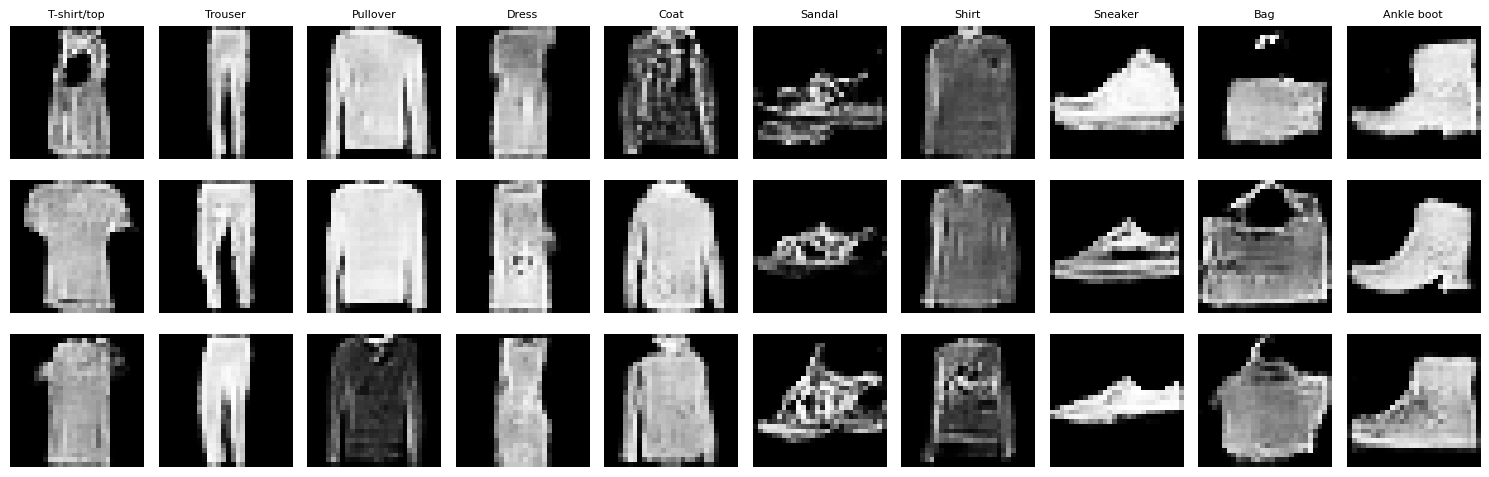

Batch 32 | Epoch 11/30:   0%|          | 0/1500 [00:00<?, ?batch/s]

Epoch [11/30] D_loss: 0.8721 G_loss: 1.5943


Batch 32 | Epoch 12/30:   0%|          | 0/1500 [00:00<?, ?batch/s]

Epoch [12/30] D_loss: 0.8746 G_loss: 1.6016


Batch 32 | Epoch 13/30:   0%|          | 0/1500 [00:00<?, ?batch/s]

...

Epoch [18/30] D_loss: 0.8855 G_loss: 1.6320


Batch 32 | Epoch 19/30:   0%|          | 0/1500 [00:00<?, ?batch/s]

Epoch [19/30] D_loss: 0.8841 G_loss: 1.6350


Batch 32 | Epoch 20/30:   0%|          | 0/1500 [00:00<?, ?batch/s]

Epoch [20/30] D_loss: 0.8849 G_loss: 1.6409


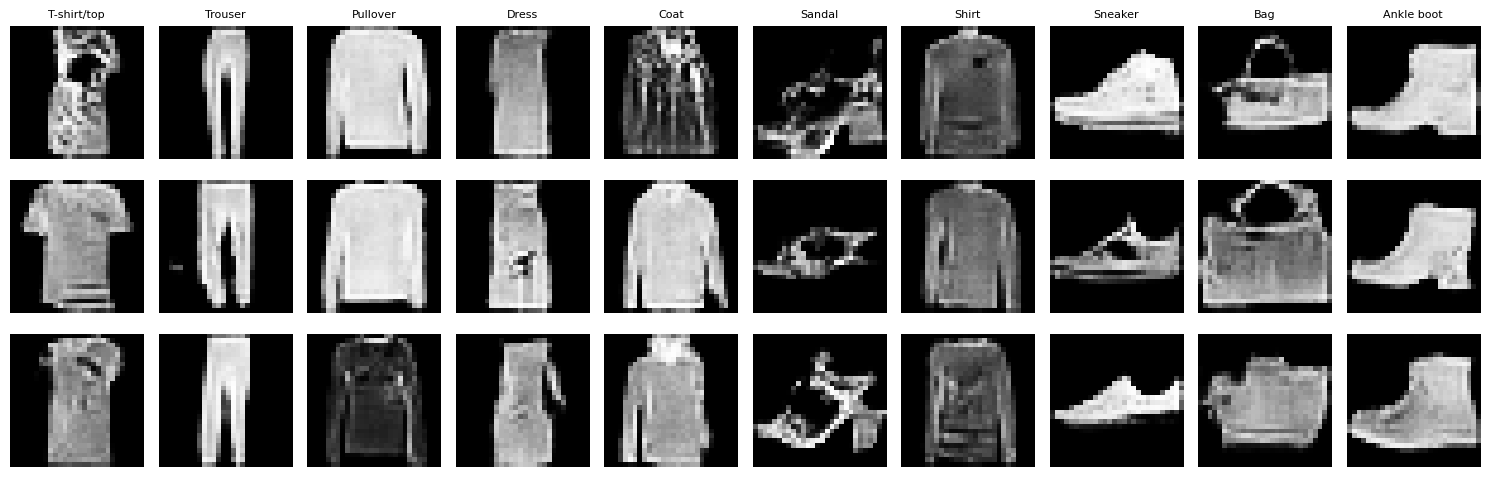

Batch 32 | Epoch 21/30:   0%|          | 0/1500 [00:00<?, ?batch/s]

Epoch [21/30] D_loss: 0.8844 G_loss: 1.6492


Batch 32 | Epoch 22/30:   0%|          | 0/1500 [00:00<?, ?batch/s]

Epoch [22/30] D_loss: 0.8843 G_loss: 1.6444


Batch 32 | Epoch 23/30:   0%|          | 0/1500 [00:00<?, ?batch/s]

...

Epoch [28/30] D_loss: 0.8733 G_loss: 1.6911


Batch 32 | Epoch 29/30:   0%|          | 0/1500 [00:00<?, ?batch/s]

Epoch [29/30] D_loss: 0.8605 G_loss: 1.7055


Batch 32 | Epoch 30/30:   0%|          | 0/1500 [00:00<?, ?batch/s]

Epoch [30/30] D_loss: 0.8669 G_loss: 1.7127


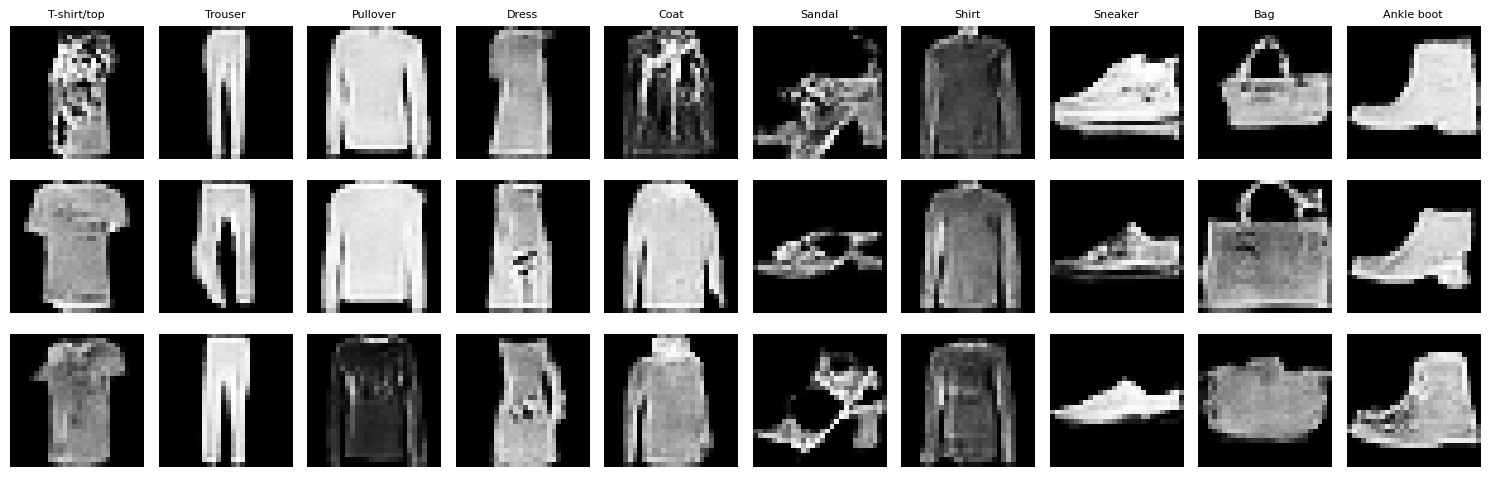

체크포인트: checkpoints/batch_experiments/batch_32/last.pt
누적 학습 시간(시각화·저장 제외): 13.8분


In [18]:
# 배치 32 학습
generator_32, history_32, checkpoint_32 = run_batch_experiment(
    batch_size=32,
    epochs=30
)

Batch 128 | Epoch 1/30:   0%|          | 0/375 [00:00<?, ?batch/s]

Epoch [1/30] D_loss: 0.6512 G_loss: 1.5849


Batch 128 | Epoch 2/30:   0%|          | 0/375 [00:00<?, ?batch/s]

Epoch [2/30] D_loss: 0.6899 G_loss: 1.5526


Batch 128 | Epoch 3/30:   0%|          | 0/375 [00:00<?, ?batch/s]

...

Epoch [8/30] D_loss: 0.9912 G_loss: 1.2095


Batch 128 | Epoch 9/30:   0%|          | 0/375 [00:00<?, ?batch/s]

Epoch [9/30] D_loss: 1.0154 G_loss: 1.1812


Batch 128 | Epoch 10/30:   0%|          | 0/375 [00:00<?, ?batch/s]

Epoch [10/30] D_loss: 1.0261 G_loss: 1.1726


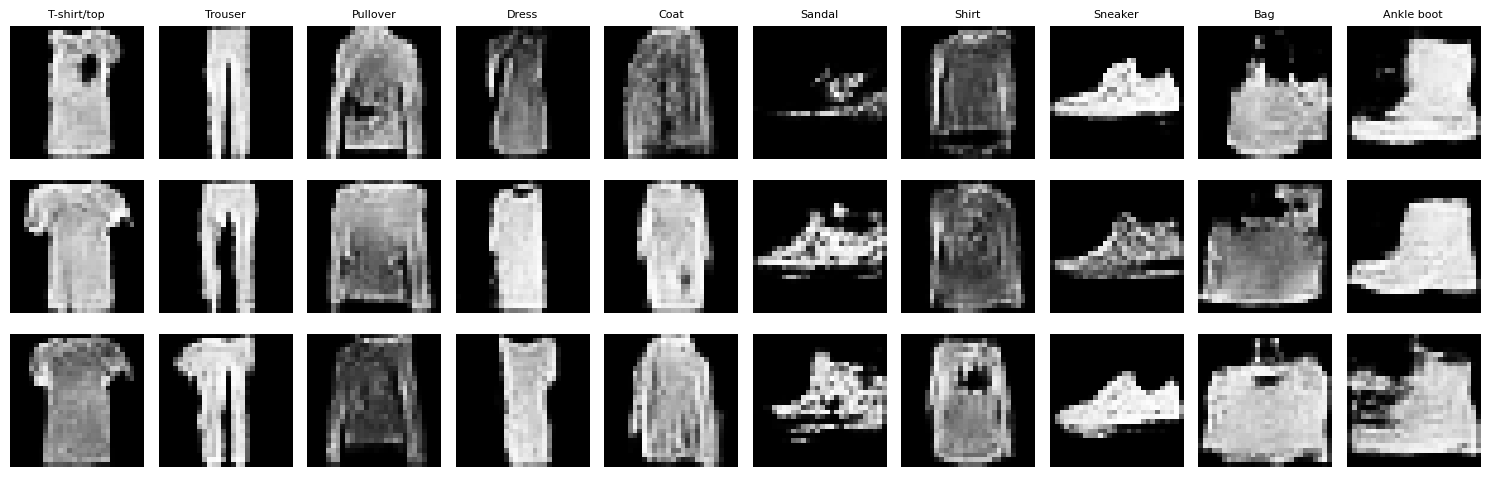

Batch 128 | Epoch 11/30:   0%|          | 0/375 [00:00<?, ?batch/s]

Epoch [11/30] D_loss: 1.0322 G_loss: 1.1669


Batch 128 | Epoch 12/30:   0%|          | 0/375 [00:00<?, ?batch/s]

Epoch [12/30] D_loss: 1.0310 G_loss: 1.1695


Batch 128 | Epoch 13/30:   0%|          | 0/375 [00:00<?, ?batch/s]

...

Epoch [18/30] D_loss: 1.0315 G_loss: 1.2004


Batch 128 | Epoch 19/30:   0%|          | 0/375 [00:00<?, ?batch/s]

Epoch [19/30] D_loss: 1.0234 G_loss: 1.2050


Batch 128 | Epoch 20/30:   0%|          | 0/375 [00:00<?, ?batch/s]

Epoch [20/30] D_loss: 1.0282 G_loss: 1.2090


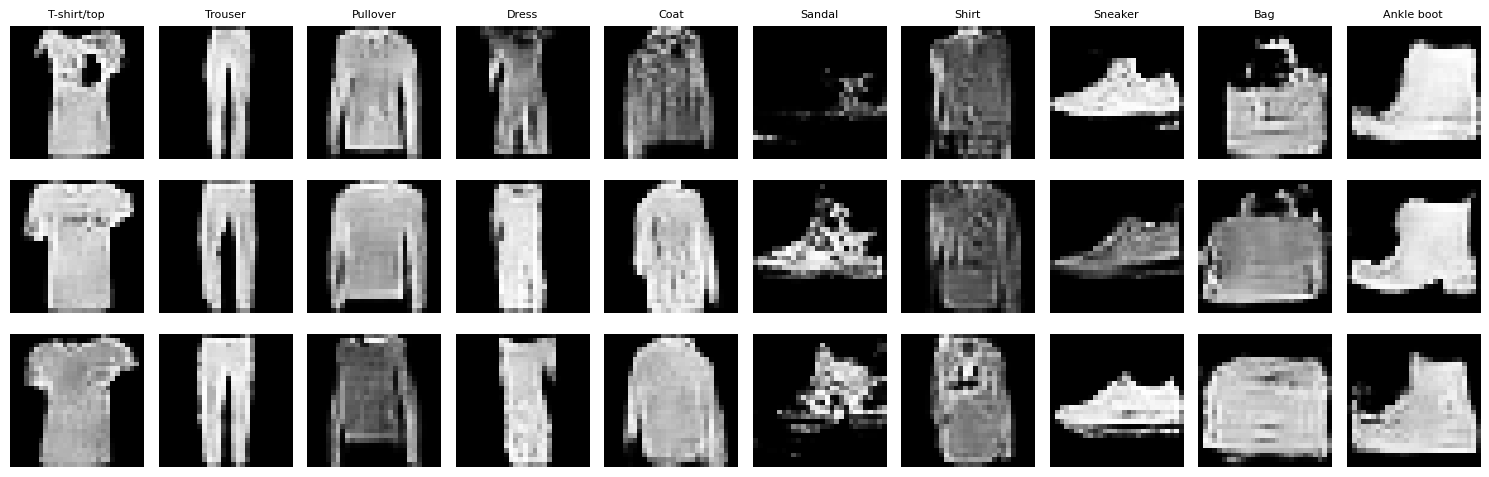

Batch 128 | Epoch 21/30:   0%|          | 0/375 [00:00<?, ?batch/s]

Epoch [21/30] D_loss: 1.0297 G_loss: 1.2124


Batch 128 | Epoch 22/30:   0%|          | 0/375 [00:00<?, ?batch/s]

Epoch [22/30] D_loss: 1.0270 G_loss: 1.2186


Batch 128 | Epoch 23/30:   0%|          | 0/375 [00:00<?, ?batch/s]

...

Epoch [28/30] D_loss: 1.0194 G_loss: 1.2398


Batch 128 | Epoch 29/30:   0%|          | 0/375 [00:00<?, ?batch/s]

Epoch [29/30] D_loss: 1.0259 G_loss: 1.2399


Batch 128 | Epoch 30/30:   0%|          | 0/375 [00:00<?, ?batch/s]

Epoch [30/30] D_loss: 1.0239 G_loss: 1.2480


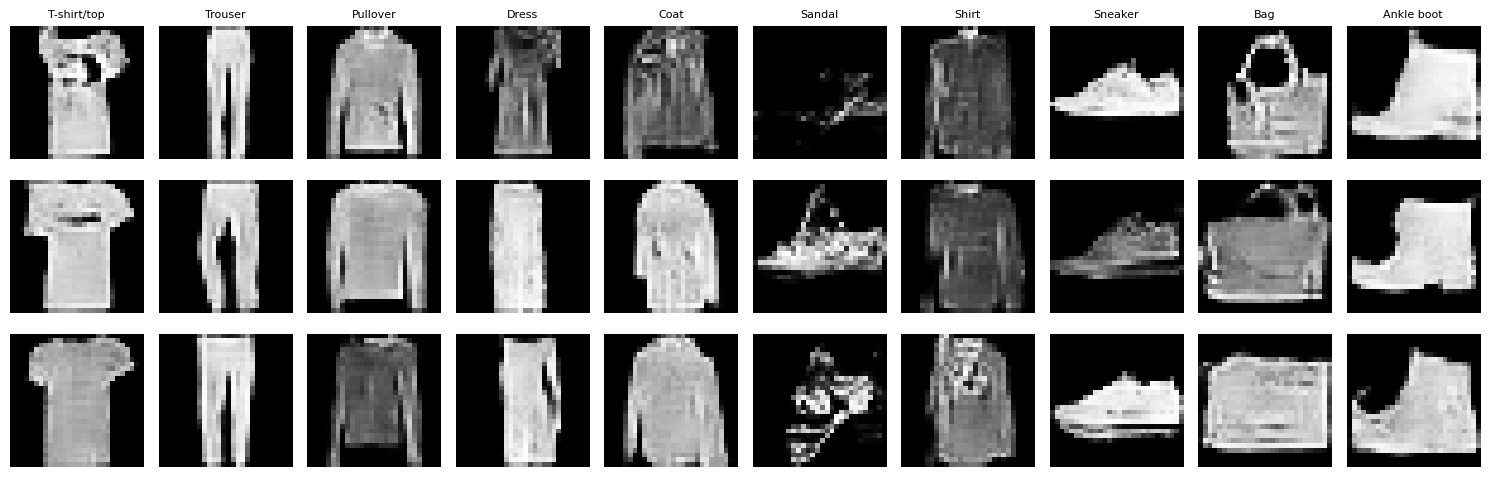

체크포인트: checkpoints/batch_experiments/batch_128/last.pt
누적 학습 시간(시각화·저장 제외): 9.4분


In [19]:
# 배치 128 학습
generator_128, history_128, checkpoint_128 = run_batch_experiment(
    batch_size=128,
    epochs=30
)

Batch 64 | Epoch 1/30:   0%|          | 0/750 [00:00<?, ?batch/s]

Epoch [1/30] D_loss: 0.6305 G_loss: 1.6579


Batch 64 | Epoch 2/30:   0%|          | 0/750 [00:00<?, ?batch/s]

Epoch [2/30] D_loss: 0.6480 G_loss: 1.7158


Batch 64 | Epoch 3/30:   0%|          | 0/750 [00:00<?, ?batch/s]

...

Epoch [8/30] D_loss: 0.9683 G_loss: 1.3064


Batch 64 | Epoch 9/30:   0%|          | 0/750 [00:00<?, ?batch/s]

Epoch [9/30] D_loss: 0.9608 G_loss: 1.3203


Batch 64 | Epoch 10/30:   0%|          | 0/750 [00:00<?, ?batch/s]

Epoch [10/30] D_loss: 0.9642 G_loss: 1.3307


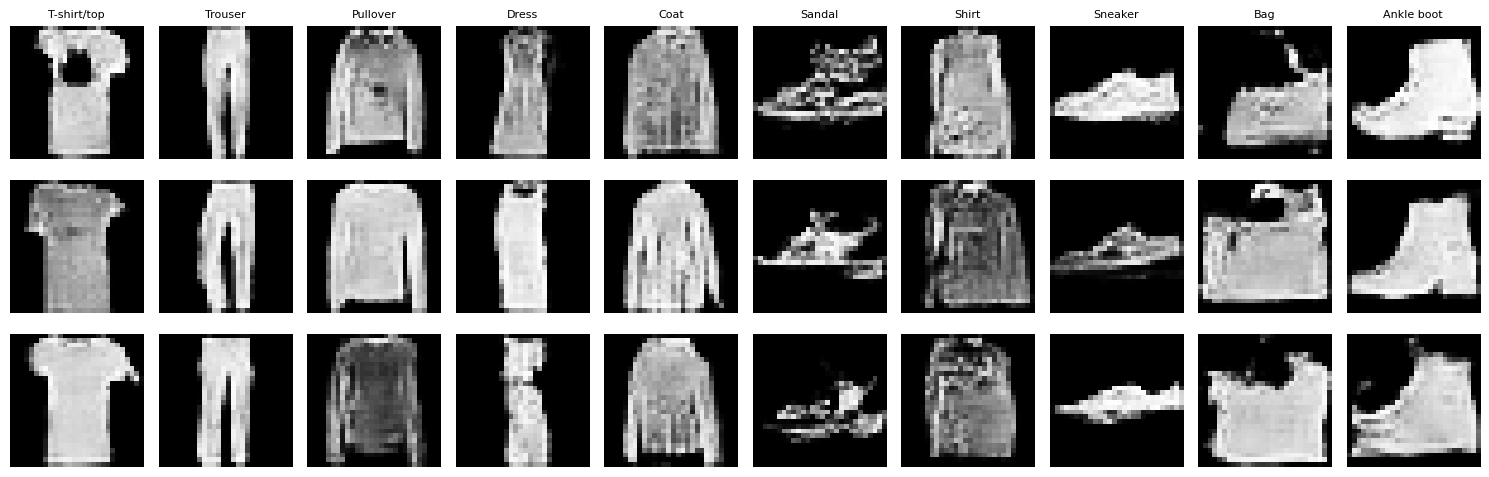

Batch 64 | Epoch 11/30:   0%|          | 0/750 [00:00<?, ?batch/s]

Epoch [11/30] D_loss: 0.9619 G_loss: 1.3415


Batch 64 | Epoch 12/30:   0%|          | 0/750 [00:00<?, ?batch/s]

Epoch [12/30] D_loss: 0.9611 G_loss: 1.3504


Batch 64 | Epoch 13/30:   0%|          | 0/750 [00:00<?, ?batch/s]

...

Epoch [18/30] D_loss: 0.9368 G_loss: 1.4192


Batch 64 | Epoch 19/30:   0%|          | 0/750 [00:00<?, ?batch/s]

Epoch [19/30] D_loss: 0.9373 G_loss: 1.4166


Batch 64 | Epoch 20/30:   0%|          | 0/750 [00:00<?, ?batch/s]

Epoch [20/30] D_loss: 0.9356 G_loss: 1.4284


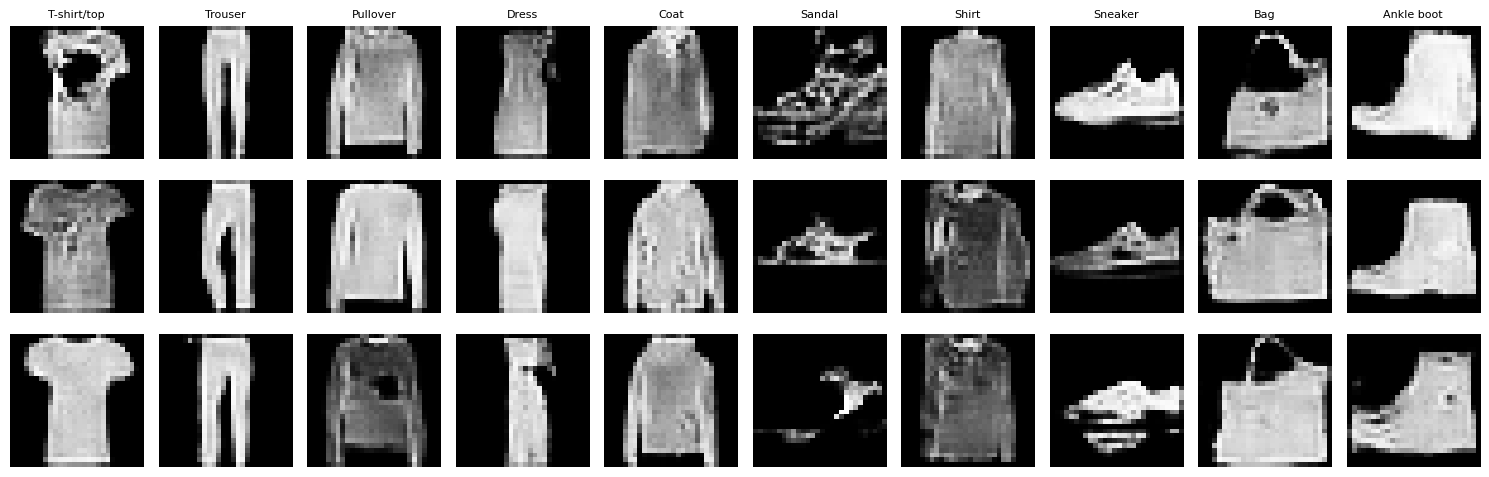

Batch 64 | Epoch 21/30:   0%|          | 0/750 [00:00<?, ?batch/s]

Epoch [21/30] D_loss: 0.9357 G_loss: 1.4349


Batch 64 | Epoch 22/30:   0%|          | 0/750 [00:00<?, ?batch/s]

Epoch [22/30] D_loss: 0.9328 G_loss: 1.4431


Batch 64 | Epoch 23/30:   0%|          | 0/750 [00:00<?, ?batch/s]

...

Epoch [28/30] D_loss: 0.9193 G_loss: 1.4957


Batch 64 | Epoch 29/30:   0%|          | 0/750 [00:00<?, ?batch/s]

Epoch [29/30] D_loss: 0.9154 G_loss: 1.5018


Batch 64 | Epoch 30/30:   0%|          | 0/750 [00:00<?, ?batch/s]

Epoch [30/30] D_loss: 0.9199 G_loss: 1.4984


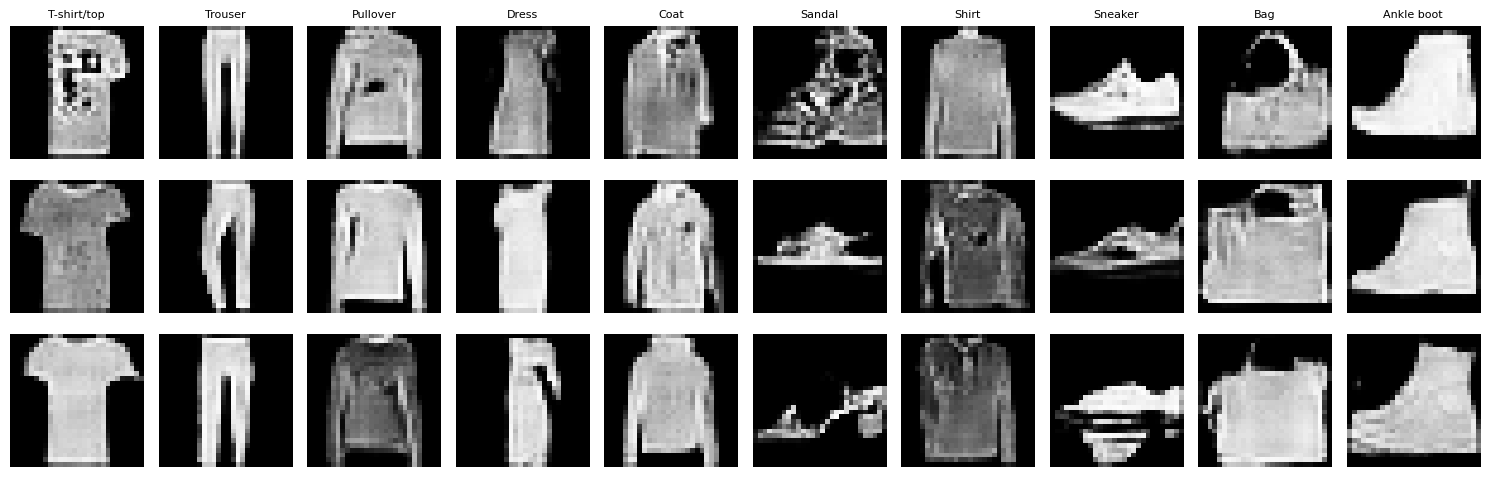

체크포인트: checkpoints/batch_experiments/batch_64/last.pt
누적 학습 시간(시각화·저장 제외): 10.4분


In [21]:
generator_64, history_64, checkpoint_64 = run_batch_experiment(
    batch_size=64,
    epochs=30
)

> batch_size=32,epochs=30이 시간이 13.8분으로 가장 높은 수치로 나왔지만, 이미지 생성에서는 가장 흔들림 없어 보여 32로 배치사이즈를 설정한다.

## 모델 평가 및 검증 - 배치 사이즈 32 기준
- 목적: 생성자가 라벨과 유사한 이미지를 생성하는지를 정성, 정량정보로 확인한다. 확인된 내용을 기반으로 성능 개선을 준비한다.

실험: Batch 32
완료 에포크: 30
평가 장치: cuda


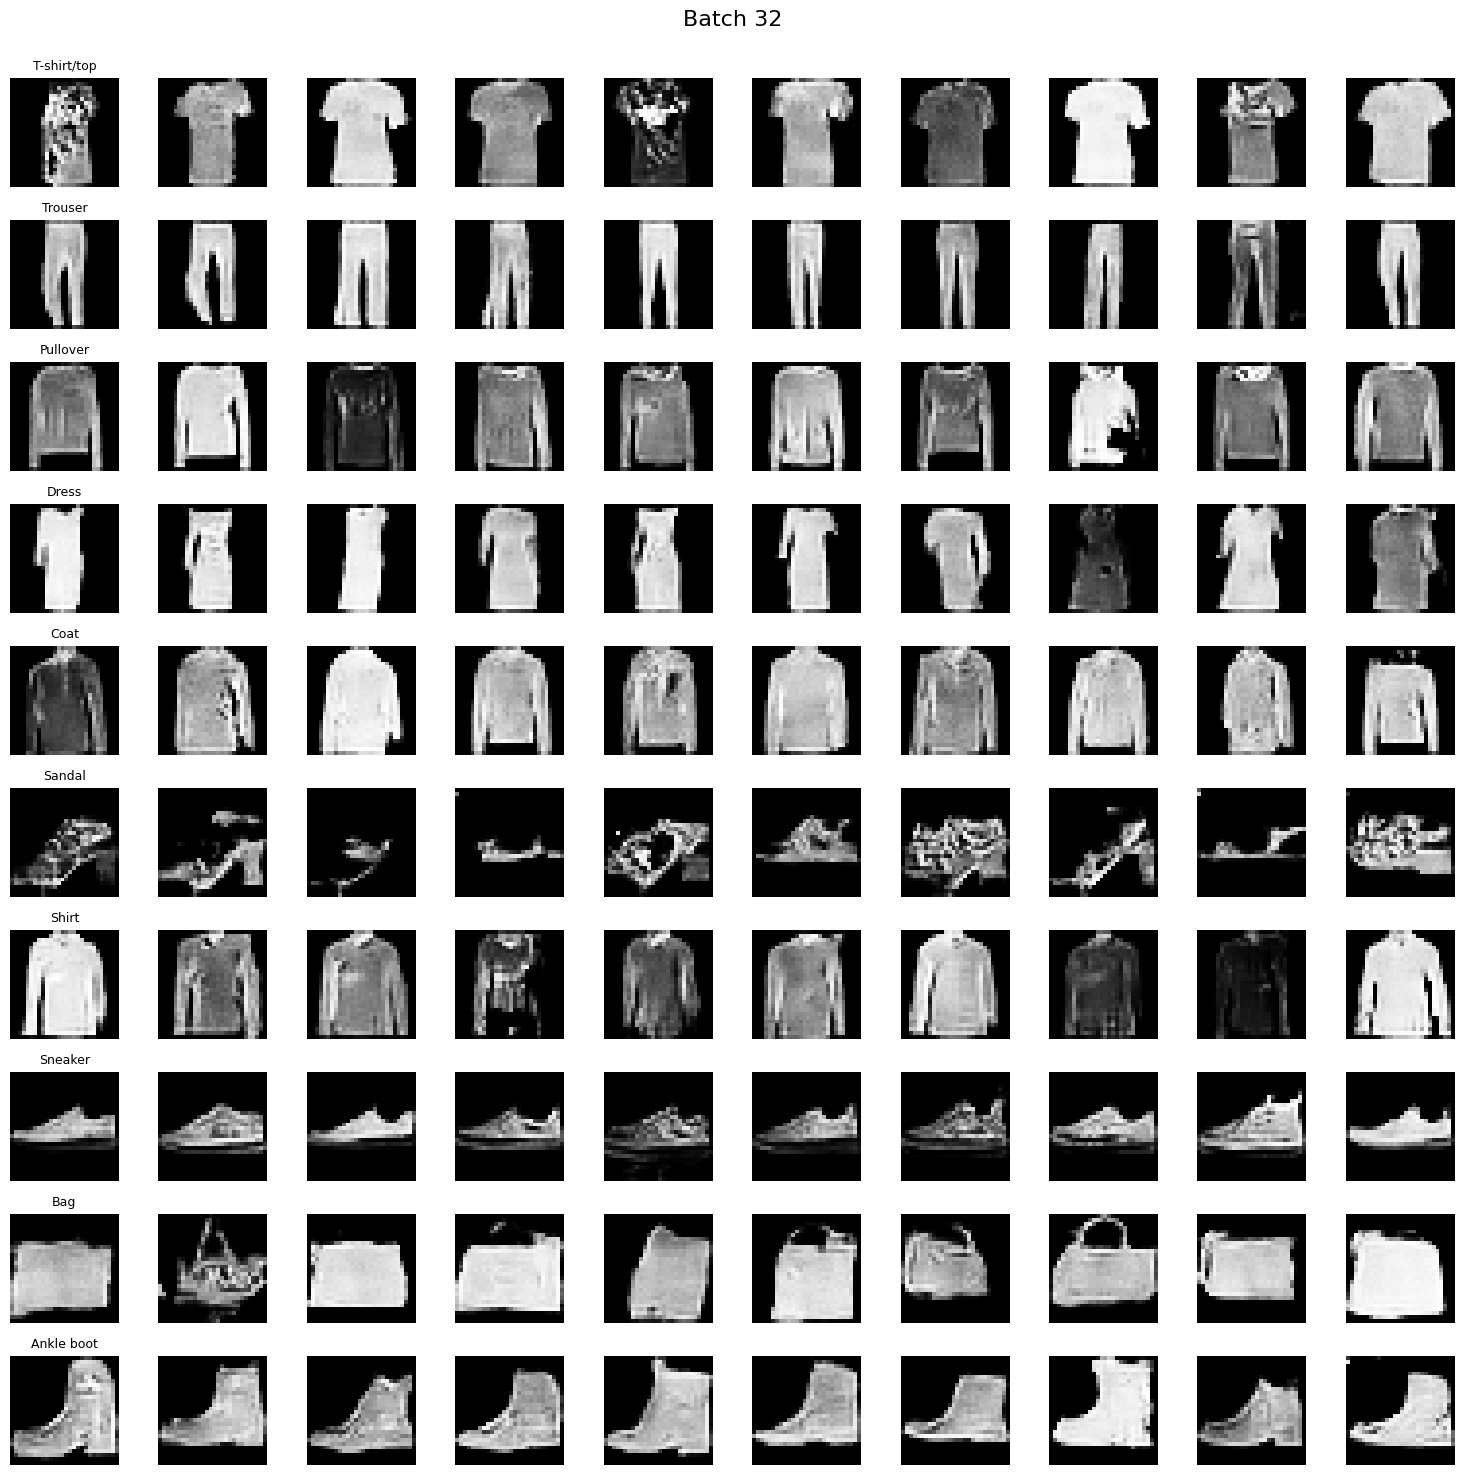

In [22]:
# 평가할 실험 선택
eval_generator = generator_32
eval_history = history_32
experiment_name = "Batch 32"

# 학습 완료 상태 확인
print("실험:", experiment_name)
print("완료 에포크:", len(eval_history["g_loss"]))
print("평가 장치:", device)

# 클래스별 10장씩 생성
eval_generator.eval()

eval_rng = torch.Generator(device="cpu").manual_seed(42)

eval_noise = torch.randn(
    num_classes * 10,
    latent_dim,
    generator=eval_rng
).to(device)

eval_labels = torch.arange(
    num_classes, device=device
).repeat_interleave(10)

with torch.inference_mode():
    generated_images = eval_generator(
        eval_noise, eval_labels
    ).cpu()

# 시각화를 위해 [-1, 1] → [0, 1]
display_images = (generated_images + 1) / 2

fig, axes = plt.subplots(
    num_classes, 10,
    figsize=(15, 15)
)

fig.suptitle(experiment_name, fontsize=16)

for idx in range(num_classes):
    for col in range(10):
        image_idx = idx * 10 + col

        axes[idx, col].imshow(
            display_images[image_idx, 0],
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[idx, col].axis("off")

        if col == 0:
            axes[idx, col].set_title(
                train_processed.classes[idx],
                fontsize=9
            )

plt.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

실험: Batch 128
완료 에포크: 30
평가 장치: cuda


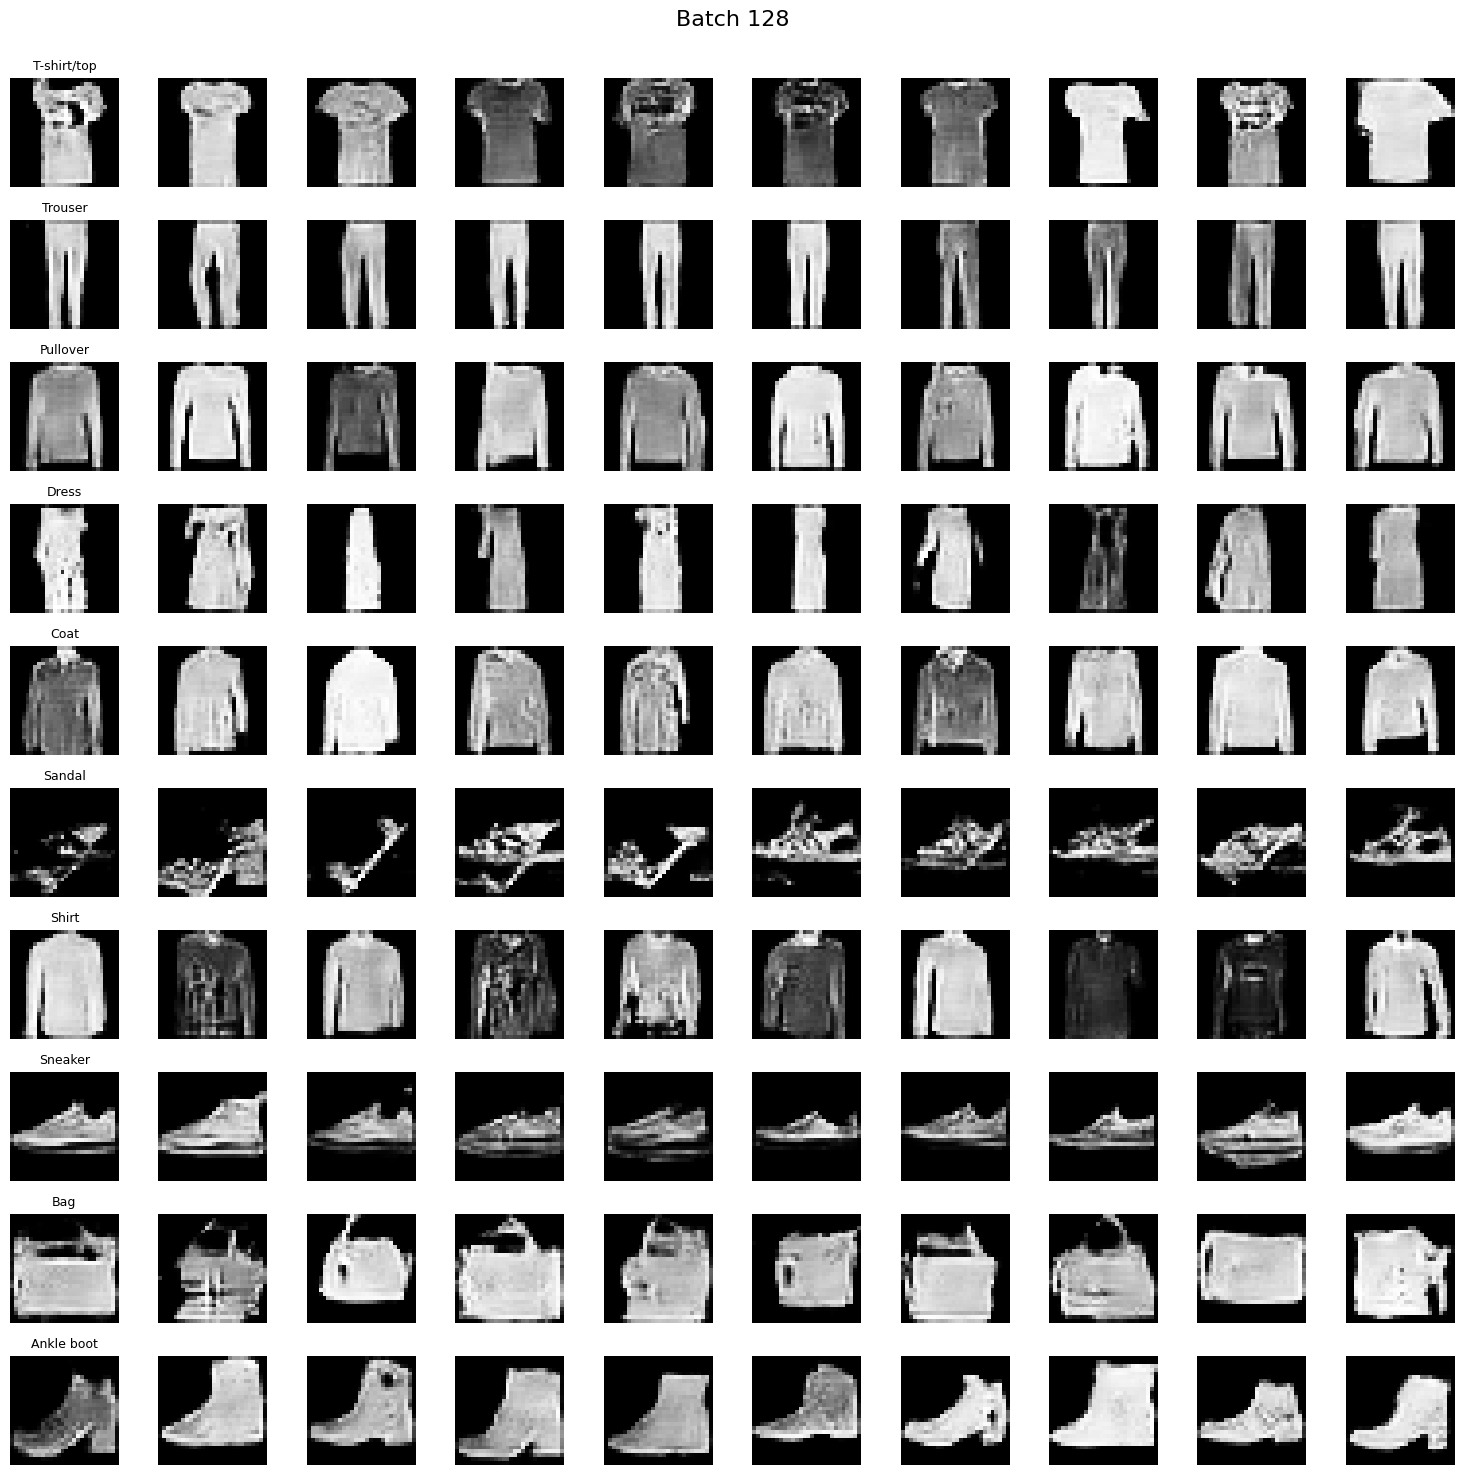

In [23]:
# 배치 사이즈 - 128

# 평가할 실험 선택
eval_generator = generator_128
eval_history = history_128
experiment_name = "Batch 128"

# 학습 완료 상태 확인
print("실험:", experiment_name)
print("완료 에포크:", len(eval_history["g_loss"]))
print("평가 장치:", device)

# 클래스별 10장씩 생성
eval_generator.eval()

eval_rng = torch.Generator(device="cpu").manual_seed(42)

eval_noise = torch.randn(
    num_classes * 10,
    latent_dim,
    generator=eval_rng
).to(device)

eval_labels = torch.arange(
    num_classes, device=device
).repeat_interleave(10)

with torch.inference_mode():
    generated_images = eval_generator(
        eval_noise, eval_labels
    ).cpu()

# 시각화를 위해 [-1, 1] → [0, 1]
display_images = (generated_images + 1) / 2

fig, axes = plt.subplots(
    num_classes, 10,
    figsize=(15, 15)
)

fig.suptitle(experiment_name, fontsize=16)

for idx in range(num_classes):
    for col in range(10):
        image_idx = idx * 10 + col

        axes[idx, col].imshow(
            display_images[image_idx, 0],
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[idx, col].axis("off")

        if col == 0:
            axes[idx, col].set_title(
                train_processed.classes[idx],
                fontsize=9
            )

plt.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()